# Thu thập và khám phá dữ liệu TMDB + IMDb

**Cập nhật ngày 19/11/2026 theo bốn câu hỏi đã chốt.** CSV đầu vào là bản nhóm tải ngày 05/11/2026.
Notebook kiểm tra cấu trúc, chất lượng, phân phối và các mối liên hệ sơ bộ theo mục 3.2 của
[đề bài](../doc/CSC17104_2026_Final_Project.pdf).

Các bảng chất lượng đếm số dòng trong CSV gốc. Phần quan hệ có mẫu riêng cho từng câu hỏi, kèm điều kiện
và số dòng trước, sau mỗi bước lọc. Phạm vi câu hỏi và người phụ trách được ghi tại
[QUESTIONS.md](../doc/QUESTIONS.md).

Chọn kernel **Python (movies-dataset)** và chạy lại toàn bộ notebook từ đầu. Notebook đọc CSV cục bộ,
thực hiện chuyển kiểu và lọc trong bộ nhớ. Các ghi chú và mã có hỗ trợ của Codex được ghi trong
[LLM_USAGE.md](../LLM_USAGE.md). Theo mục 6 của đề, nhóm cần hiểu mã, kiểm chứng kết quả
và tự viết phần phân tích, câu trả lời, reflection dùng trong bài nộp.

## 1. Nguồn và bối cảnh

- **Chủ đề.** Bộ dữ liệu mô tả các tác phẩm trong danh mục phim TMDB được liên kết với dữ liệu IMDb.
  Dữ liệu bao gồm đặc điểm tác phẩm như thể loại, ngôn ngữ, thời lượng và ngày phát hành, cùng ngân sách, doanh thu,
  điểm đánh giá và số lượt chấm. Nhóm dùng dữ liệu để tìm hiểu mối liên hệ giữa đặc điểm phim, kết quả tài chính
  và đánh giá của khán giả trên hai nền tảng.
- **Nguồn gốc.** Nhóm sử dụng file CSV trong bộ [TMDB + IMDB Merged Movies Dataset](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset/data)
  do **Tejas Garg (`ggtejas`)** công bố trên Kaggle. Trong phần mô tả, tác giả dẫn hai nguồn dữ liệu.

  - **TMDB.** Tác giả lấy thông tin phim như tên, ngày phát hành và doanh thu từ [bộ dữ liệu TMDB do `asaniczka` đăng trên Kaggle](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies).
  - **IMDb.** Tác giả sử dụng [IMDb Non-Commercial Datasets](https://developer.imdb.com/non-commercial-datasets/)
    do IMDb cung cấp để bổ sung thông tin như đạo diễn, biên kịch, diễn viên, điểm và số lượt chấm trên IMDb.

  Phiên bản đầu tiên trên Kaggle (**v1**) ghi ngày **13/11/2024**. Nhóm tải bản **v578** ngày **05/11/2026**,
  cùng ngày bản này được cập nhật trên Kaggle. SHA-256 của CSV nhóm dùng khớp với CSV tải lại từ v578.
- **Giấy phép:** [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) của bản tổng hợp;
  ghi nguồn và các thay đổi, sử dụng phi thương mại, tuân thủ điều kiện chia sẻ tương tự.
  Đối chiếu thêm điều kiện của [IMDb](https://developer.imdb.com/non-commercial-datasets/)
  và [TMDB](https://developer.themoviedb.org/docs/faq); nhãn của bản tổng hợp không thay thế điều kiện nguồn.
- **Cách thu thập dữ liệu (Collection method).** Nhóm tải CSV đã được tác giả tổng hợp từ hai nguồn có sẵn.
  Tác giả chưa mô tả chi tiết quy tắc ghép dữ liệu hay cách xử lý mã trùng.

  - **Phạm vi tác phẩm.** Phạm vi là các tác phẩm có trong bản ghép v578. Mức độ bao phủ toàn bộ
    danh mục TMDB và IMDb chưa được xác nhận. CSV thiếu trường `titleType` để phân biệt chắc chắn phim điện ảnh,
    phim ngắn và tác phẩm truyền hình.
  - **Thời kỳ dữ liệu.** Trong CSV, ngày phát hành ghi nhận nằm từ **09/12/1874** đến **13/10/2029**.
    Khoảng này có cả ngày sau ngày nhóm tải. Tác giả chưa công bố thời điểm trích xuất từng nguồn,
    nên thời điểm ghi nhận điểm và lượt chấm của mỗi nền tảng chưa được xác minh.
  - **Giới hạn và khả năng sai lệch.** Các dòng trong CSV có thể thiên về những tác phẩm có thông tin ở cả hai
    nền tảng. CSV thiếu đơn vị tiền tệ theo từng dòng và chưa có xác nhận về cách chuẩn hóa hay điều chỉnh lạm phát.
    Để tính lợi nhuận thực còn cần các khoản chi phí và khoản phân chia doanh thu ngoài những gì CSV ghi nhận.
- **Lý do chọn:** Chủ đề phim ảnh gần gũi. Dữ liệu có thông tin tài chính, thuộc tính đa nhãn và điểm từ hai nền tảng,
  phù hợp tìm hiểu các khác biệt theo nhóm và theo thời gian.

Tài liệu IMDb định nghĩa `averageRating` là điểm trung bình có trọng số và `numVotes` là số lượt chấm;
`tconst` là mã tác phẩm. Metadata nguồn là mô tả của người công bố, không chứng minh chất lượng từng dòng dữ liệu.

Bốn câu hỏi xác định trọng tâm khám phá như sau.

| Câu hỏi | Các cột cần khám phá sâu | Thông tin cần chuẩn bị |
| --- | --- | --- |
| Q1. IMDb và TMDB chấm lệch nhau thế nào? | `vote_average`, `vote_count`, `averageRating`, `numVotes`, `genres`, `release_date` | Khoảng điểm và số lượt chấm, số cặp đủ điều kiện ở các ngưỡng và độ đầy đủ của thể loại. |
| Q2. Dự đoán điểm IMDb từ hồ sơ phim | `averageRating`, `runtime`, `genres`, `original_language`, `release_date` | Độ đầy đủ của đầu vào, phân phối mục tiêu trên phần trước 2020 và số phim trong hai khoảng thời gian. |
| Q3. Phim có ngày càng dài hơn? | `runtime`, `release_date`, `genres`, `original_language`, `status` | Số 0 và cực trị thời lượng, số tác phẩm từng giai đoạn và thành phần thể loại, ngôn ngữ. |
| Q4. Cùng mức ngân sách, thể loại nào có doanh thu cao hơn? | `budget`, `revenue`, `genres`, `release_date`, `original_language`, `status` | Số 0, cực trị tài chính, đơn vị tiền tệ, số mẫu trong các nhóm thể loại, ngân sách và giai đoạn. |

`id` và `tconst` dùng để kiểm tra mã phim cho cả bốn câu. Từ điển ở mục 2 tóm tắt đủ 29 cột.
Các biểu đồ tập trung vào những cột trong bảng này.

In [1]:
from pathlib import Path
import csv
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'environment.yml').is_file() and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục repository hoặc notebooks/.')
RAW_PATH = ROOT / 'data/raw/TMDB  IMDB Movies Dataset.csv'
if not RAW_PATH.is_file():
    raise FileNotFoundError(f'Tải CSV theo README và đặt tại: {RAW_PATH}')
DOWNLOAD_DATE = pd.Timestamp('2026-11-05')
RANDOM_STATE = 42
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                   'seaborn': sns.__version__, 'executable': sys.executable}, name='Môi trường'))

def file_sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw_sha256 = file_sha256(RAW_PATH)
print('SHA-256:', raw_sha256)
# Giữ nguyên chuỗi như NA/N/A/NULL nếu có; chỉ ô trống và ký hiệu IMDb \N là thiếu.
movies = pd.read_csv(RAW_PATH, low_memory=False, keep_default_na=False, na_values=['', r'\N'])
n = len(movies)
display(pd.Series({'dòng': n, 'cột': movies.shape[1], 'byte': RAW_PATH.stat().st_size,
                   'SHA-256': raw_sha256, 'ngày tải': str(DOWNLOAD_DATE.date())}, name='CSV cục bộ'))
display(movies[['id', 'tconst', 'title', 'release_date', 'budget', 'revenue']].head())

Python                                                  3.11.13
pandas                                                    2.2.3
numpy                                                     2.2.6
matplotlib                                               3.10.3
seaborn                                                  0.13.2
executable    /home/khangtran/miniconda3/envs/movies-dataset...
Name: Môi trường, dtype: object

SHA-256: f1c78500acd6a953492bdaa2413015b54baa082a213628e8ecd96be4e5dfe5f4


dòng                                                   443656
cột                                                        29
byte                                                282010663
SHA-256     f1c78500acd6a953492bdaa2413015b54baa082a213628...
ngày tải                                           2026-11-05
Name: CSV cục bộ, dtype: object

,id,tconst,title,release_date,budget,revenue
0,27205,tt1375666,Inception,2010-07-15,160000000,825532764
1,157336,tt0816692,Interstellar,2014-11-05,165000000,701729206
2,155,tt0468569,The Dark Knight,2008-07-16,185000000,1004558444
3,19995,tt0499549,Avatar,2009-12-15,237000000,2923706026
4,24428,tt0848228,The Avengers,2012-04-25,220000000,1518815515


## 2. Tổng quan về cấu trúc CSV và mã phim

Phần này kiểm tra số dòng, số cột, các dòng trống và mã phim xuất hiện nhiều lần. Một dòng CSV là một bộ thông tin sau khi ghép hai nguồn. Cùng một tác phẩm có thể có nhiều dòng.

Các ô code từ đây được thu gọn mặc định. Mỗi bảng hoặc hình đi cùng một đoạn giải thích ngắn. Bạn có thể bấm phần code đã thu gọn để xem cách tính, hoặc chạy lại toàn bộ notebook như bình thường.

### 2.1. File có dòng trống hoặc sai số ô không?

File có 29 cột nên một dòng đầy đủ cấu trúc có 29 vị trí, dù một vài ô có thể trống. Bảng đếm dòng CSV sau hàng tiêu đề. Văn bản xuống dòng trong một ô vẫn được tính trong cùng một dòng dữ liệu.

In [2]:
empty_records = 0
all_blank_records = 0
wrong_width_records = 0
csv_records = 0
with RAW_PATH.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
        csv_records += 1
        if not row:
            empty_records += 1
        else:
            all_blank_records += all(not value.strip() for value in row)
            wrong_width_records += len(row) != len(header)

missing = movies.isna().copy()
space_only = pd.Series(0, index=movies.columns, dtype='int64')
for col in movies.select_dtypes(include=['object', 'string']):
    blank = movies[col].str.fullmatch(r'\s+', na=False)
    space_only[col] = blank.sum()
    missing[col] |= blank

structure = pd.Series({
    'Tổng số dòng trong CSV, kể cả dòng trống': csv_records,
    'Dòng trống hoàn toàn': empty_records,
    'Dòng có ô nhưng tất cả ô đều trống': all_blank_records,
    f'Dòng có số ô khác {len(header)}': wrong_width_records,
    'Dòng thiếu tất cả giá trị sau khi đọc CSV': int(missing.all(axis=1).sum()),
    'Dòng giống hệt một dòng trước đó': int(movies.duplicated().sum()),
})
display(structure.to_frame('Số lượng'))

,Số lượng
"Tổng số dòng trong CSV, kể cả dòng trống",443656
Dòng trống hoàn toàn,0
Dòng có ô nhưng tất cả ô đều trống,0
Dòng có số ô khác 29,0
Dòng thiếu tất cả giá trị sau khi đọc CSV,0
Dòng giống hệt một dòng trước đó,0


Bảng có sáu phép kiểm tra riêng.

| Hàng kiểm tra | Cách đọc |
| --- | --- |
| Tổng số dòng trong CSV, kể cả dòng trống | Số dòng dữ liệu sau tiêu đề. |
| Dòng trống hoàn toàn | Dòng không có chữ hay dấu phân cách. |
| Dòng có ô nhưng tất cả ô đều trống | Các dấu phẩy vẫn chia thành ô, nhưng mọi ô đều trống hoặc chỉ có dấu cách. |
| Dòng có số ô khác 29 | Số ô đọc được khác số cột trong tiêu đề. Một ô trống vẫn được tính là một ô. |
| Dòng thiếu tất cả giá trị sau khi đọc CSV | Sau khi nhận diện ô trống và ký hiệu thiếu như `\N`, mọi ô trong dòng đều thiếu. |
| Dòng giống hệt một dòng trước đó | Số bản sao dư khi so toàn bộ 29 cột. |

Các phép kiểm tra có thể cùng đếm một dòng. Trên CSV này, năm phép kiểm tra vấn đề đều cho kết quả 0. Việc một dòng thiếu vài ô được xét riêng ở mục 5.

### 2.2. Mã phim có bị lặp không?

`id` là mã tác phẩm trên **TMDb**, còn `tconst` là mã trên **IMDb**. Bảng kiểm tra hai mã riêng biệt.

In [3]:
key_rows = []
for col in ['id', 'tconst']:
    known = movies.loc[~missing[col], col]
    key_rows.append([col, missing[col].sum(), known.nunique(), known.duplicated().sum(),
                     known.duplicated(keep=False).sum()])
key_audit = pd.DataFrame(key_rows, columns=['Cột mã', 'Dòng thiếu mã', 'Số mã khác nhau',
                                            'Dòng lặp sau lần đầu', 'Dòng có mã lặp'])
display(key_audit)

,Cột mã,Dòng thiếu mã,Số mã khác nhau,Dòng lặp sau lần đầu,Dòng có mã lặp
0,id,0,429762,13894,17372
1,tconst,0,426661,16995,18467


**Số mã khác nhau** là số mã riêng biệt xuất hiện trong CSV. **Dòng lặp sau lần đầu** bỏ qua lần đầu của mỗi mã rồi đếm các lần còn lại. **Dòng có mã lặp** tính cả lần đầu.

Ví dụ, mã xuất hiện 3 lần có 2 dòng lặp sau lần đầu và 3 dòng có mã lặp. Một dòng có thể được tính trong cả hàng `id` và hàng `tconst`, nên hai số dòng lặp phải được đọc riêng.

### 2.3. Hai mã được nối với nhau như thế nào?

Một mã TMDb có thể xuất hiện ở nhiều dòng nhưng vẫn chỉ đi với cùng một mã IMDb. Bảng dưới kiểm tra chiều nối đó và chiều ngược lại, đồng thời kiểm tra dạng của mã.

In [4]:
id_to_imdb = movies.groupby('id')['tconst'].nunique()
imdb_to_id = movies.groupby('tconst')['id'].nunique()
display(pd.Series({'Mã TMDB đi với nhiều mã IMDb': int(id_to_imdb.gt(1).sum()),
                   'Mã IMDb đi với nhiều mã TMDB': int(imdb_to_id.gt(1).sum()),
                   'Mã TMDB bằng 0 hoặc âm': int(movies.id.le(0).sum()),
                   'Mã IMDb sai dạng tt + chữ số': int((~movies.tconst.str.fullmatch(r'tt\d+', na=False)).sum())}))

Mã TMDB đi với nhiều mã IMDb       0
Mã IMDb đi với nhiều mã TMDB    1424
Mã TMDB bằng 0 hoặc âm             0
Mã IMDb sai dạng tt + chữ số       0
dtype: int64

Có **1.424 mã IMDb** đi với nhiều mã TMDb. Cần kiểm tra thông tin giữa các dòng theo cả hai chiều trước khi chọn cách gộp.

Hai bảng dưới xét riêng nhóm cùng mã TMDb và nhóm cùng mã IMDb. Bảng đầu ghi số nhóm mã lặp được kiểm tra. Bảng sau đếm có bao nhiêu nhóm khác nhau ở từng cột. Một ô có giá trị và một ô trống trong cùng nhóm cũng được tính là thông tin khác nhau.

Mỗi cột có số nhóm được kiểm tra khác nhau, nên cần đọc kết quả cùng bảng đầu.

In [5]:
conflicts_by_key = {}
repeated_key_groups = []
for key, platform in [('id', 'TMDb'), ('tconst', 'IMDb')]:
    repeated_rows = movies.loc[movies[key].notna() & movies[key].duplicated(keep=False)]
    repeated_key_groups.append([platform, key, repeated_rows[key].nunique(), len(repeated_rows)])
    conflicts_by_key[platform] = repeated_rows.groupby(key).nunique(dropna=False).gt(1).sum()

display(pd.DataFrame(repeated_key_groups, columns=[
    'Nền tảng', 'Cột mã', 'Số mã lặp được kiểm tra', 'Số dòng mang các mã này']))
conflict_counts = pd.DataFrame(conflicts_by_key).fillna(0).astype(int)
conflict_counts = conflict_counts.sort_values(['TMDb', 'IMDb'], ascending=False)
display(conflict_counts.rename(columns={
    'TMDb': 'Số mã TMDb có thông tin khác nhau',
    'IMDb': 'Số mã IMDb có thông tin khác nhau',
}).rename_axis('Cột được so sánh'))

,Nền tảng,Cột mã,Số mã lặp được kiểm tra,Số dòng mang các mã này
0,TMDb,id,3478,17372
1,IMDb,tconst,1472,18467


,Số mã TMDb có thông tin khác nhau,Số mã IMDb có thông tin khác nhau
Cột được so sánh,,
cast,3429,975
popularity,51,1334
release_date,39,1067
genres,37,1110
poster_path,35,1311
production_companies,22,804
spoken_languages,20,896
production_countries,20,834
runtime,14,844


Cách đọc ví dụ trong bảng trên như sau.

| Cột | Cùng mã TMDb | Cùng mã IMDb |
| --- | --- | --- |
| `cast` | 3.429 nhóm khác danh sách diễn viên | 975 nhóm khác danh sách diễn viên |
| `release_date` | 39 nhóm khác ngày phát hành | 1.067 nhóm khác ngày phát hành |
| `budget` | 2 nhóm khác ngân sách | 199 nhóm khác ngân sách |

Bảng kiểm tra **3.478 mã TMDb lặp** và **1.472 mã IMDb lặp**. Khi cùng mã IMDb nối với nhiều mã TMDb, thông tin lấy từ TMDb như tên phim, ngày phát hành hoặc ngân sách có thể khác nhau giữa các dòng. Các cột IMDb `averageRating`, `numVotes`, `directors` và `writers` hiện nhất quán trong các nhóm cùng mã IMDb. Muốn gộp, nhóm cần đối chiếu xem các dòng có thực sự mô tả cùng tác phẩm và chọn cách xử lý xung đột.

Bảng tiếp theo liệt kê 10 mã IMDb xuất hiện nhiều dòng nhất. `Số mã TMDB khác nhau` cho biết mỗi mã IMDb đang nối với bao nhiêu mục trên TMDb.

In [6]:
display(movies.groupby('tconst').agg(so_dong=('id', 'size'), so_id=('id', 'nunique'))
        .sort_values('so_dong', ascending=False).head(10)
        .rename(columns={'so_dong': 'Số dòng có mã IMDb này', 'so_id': 'Số mã TMDB khác nhau'}))

,Số dòng có mã IMDb này,Số mã TMDB khác nhau
tconst,,
tt32094375,3996,148
tt26900526,1892,86
tt1757779,810,45
tt13904644,702,54
tt22075376,406,29
tt29703523,261,29
tt0813980,247,19
tt5719786,238,34
tt2705436,193,17


### 2.4. Mẫu dùng cho các mối liên hệ sơ bộ

Giữ những dòng có **cả hai mã đều chỉ xuất hiện một lần trong toàn bộ CSV**. Cách này loại toàn bộ các nhóm mã lặp, kể cả các nhóm chỉ khác diễn viên, vì quy tắc gộp chưa được xác định. Mẫu còn lại có thể khác thành phần của CSV gốc, nên bảng dưới đối chiếu một số đặc điểm của hai mẫu.

Cột **Cả ngân sách và doanh thu dương (%)** đếm các dòng có đồng thời hai giá trị lớn hơn 0. Tỷ lệ dùng tổng số dòng của từng mẫu làm mẫu số.

In [7]:
unique_keys = (~movies.id.duplicated(keep=False) & ~movies.tconst.duplicated(keep=False)
               & ~missing.id & ~missing.tconst)
base_raw = movies.loc[unique_keys]
key_sample = pd.DataFrame([
    ['CSV gốc', n, 0],
    ['Cả hai mã chỉ xuất hiện một lần', len(base_raw), n - len(base_raw)],
], columns=['Mẫu', 'Số dòng giữ lại', 'Số dòng bị loại'])
display(key_sample)
base_profile = pd.DataFrame({name: {
    'Ngân sách dương (%)': 100 * frame.budget.gt(0).mean(),
    'Doanh thu dương (%)': 100 * frame.revenue.gt(0).mean(),
    'Cả ngân sách và doanh thu dương (%)': 100 * (frame.budget.gt(0) & frame.revenue.gt(0)).mean(),
    'Thiếu thể loại (%)': 100 * missing.loc[frame.index, 'genres'].mean(),
    'Ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
} for name, frame in [('CSV gốc', movies), ('Hai mã chỉ xuất hiện một lần', base_raw)]}).T
display(base_profile.round(2))

,Mẫu,Số dòng giữ lại,Số dòng bị loại
0,CSV gốc,443656,0
1,Cả hai mã chỉ xuất hiện một lần,425189,18467


,Ngân sách dương (%),Doanh thu dương (%),Cả ngân sách và doanh thu dương (%),Thiếu thể loại (%),Ngôn ngữ gốc en (%)
CSV gốc,6.84,3.75,2.35,18.89,54.76
Hai mã chỉ xuất hiện một lần,6.72,3.79,2.39,17.46,53.58


### 2.5. Các cột có ý nghĩa gì và phục vụ câu hỏi nào?

Hai bảng dưới tóm tắt ý nghĩa, kiểu dữ liệu và hướng xử lý dự kiến cho **29 cột**. `int64` là số nguyên, `float64` là số thập phân, `bool` là đúng/sai, còn `object` hoặc `str` là văn bản. Mã `id` được lưu dưới dạng số nhưng dùng để nhận diện tác phẩm.

Bảng đầu gồm các cột trực tiếp phục vụ Q1–Q4. `vote_average` và `averageRating` đều tổng hợp lượt chấm của người dùng trên nền tảng tương ứng. `vote_count` và `numVotes` là số lượt chấm cho mỗi tác phẩm.

Khi chuẩn bị dữ liệu phân tích, nhóm chuyển `release_date` sang kiểu ngày để lấy năm phát hành và loại các cột đường dẫn ảnh (`poster_path`, `backdrop_path`) khỏi tập biến phân tích Q1–Q4. Xem cách xử lý dữ liệu thiếu và kế hoạch tiền xử lý ở mục 7.2.

In [8]:
column_notes = {
    'id': ('Mã tác phẩm TMDB', 'Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số'),
    'title': ('Tên tác phẩm', 'Giữ để kiểm tra ví dụ, không dùng tên làm khóa'),
    'vote_average': ('Điểm TMDB trên thang 0–10', 'Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra'),
    'vote_count': ('Số lượt chấm TMDB', 'Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm'),
    'status': ('Trạng thái sản xuất/phát hành', 'Giữ để lọc Released trong Q1–Q4'),
    'release_date': ('Ngày phát hành được ghi nhận', 'Chuyển sang datetime để lấy năm và giai đoạn. Q2 dùng năm làm đầu vào và để chia tập.'),
    'revenue': ('Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng số 0. Mẫu Q4 giữ giá trị dương và cần xác minh đơn vị.'),
    'runtime': ('Thời lượng theo phút', 'Q2 dự kiến đánh dấu số 0 là thiếu và điền trung vị từ tập huấn luyện. Q3 dùng thời lượng dương.'),
    'adult': ('Cờ nội dung người lớn TMDB', 'Giữ kiểu boolean để kiểm tra chất lượng. Ngoài phạm vi Q1–Q4.'),
    'backdrop_path': ('Đường dẫn ảnh nền', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'budget': ('Ngân sách được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng số 0. Mẫu Q4 giữ giá trị dương và cần xác minh đơn vị.'),
    'homepage': ('Trang web của tác phẩm', 'Bỏ khỏi mô hình nếu không dùng; kiểm tra ô khoảng trắng'),
    'tconst': ('Mã tác phẩm IMDb', 'Giữ chuỗi, kiểm tra lặp và quan hệ với id'),
    'original_language': ('Mã ngôn ngữ gốc', 'Giữ để phân nhóm. Q2 dự kiến mã hóa và gom mã hiếm dựa trên tập huấn luyện.'),
    'original_title': ('Tên nguyên gốc', 'Giữ để đối chiếu; không suy ra khóa duy nhất'),
    'overview': ('Tóm tắt nội dung', 'Có thể bỏ ở phân tích dạng bảng; không tự điền văn bản'),
    'popularity': ('Chỉ số phổ biến TMDB tại thời điểm nguồn', 'Giữ kiểu số để khám phá tương quan. Loại khỏi đầu vào Q2.'),
    'poster_path': ('Đường dẫn poster', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'tagline': ('Câu giới thiệu', 'Có thể bỏ khi không làm NLP'),
    'genres': ('Các thể loại, nhiều nhãn trên một dòng', 'Tách theo dấu phẩy và loại nhãn lặp. Q2 dự kiến mã hóa đa nhãn và đánh dấu thiếu.'),
    'production_companies': ('Các công ty sản xuất', 'Đa nhãn; kiểm tra dấu phân cách trước khi tách'),
    'production_countries': ('Các quốc gia sản xuất', 'Đa nhãn; giữ thông tin thiếu'),
    'spoken_languages': ('Các ngôn ngữ được sử dụng', 'Đa nhãn, khác ngôn ngữ gốc'),
    'keywords': ('Từ khóa nội dung', 'Đa nhãn; có thể bỏ nếu ngoài hướng câu hỏi'),
    'directors': ('Tên đạo diễn', 'Có thể nhiều người; tên không bảo đảm định danh duy nhất'),
    'writers': ('Tên biên kịch', 'Có thể nhiều người; không tự gộp người trùng tên'),
    'averageRating': ('Điểm trung bình có trọng số IMDb, thang 1–10', 'Dùng cùng numVotes để kiểm tra điểm hợp lệ. Là biến mục tiêu của Q2.'),
    'numVotes': ('Số lượt chấm IMDb', 'Q1 dùng để lọc theo ngưỡng. Q2 dùng để xác nhận có lượt chấm khi chọn mẫu.'),
    'cast': ('Danh sách diễn viên', 'Kiểm tra khác biệt giữa các dòng cùng mã; chưa gộp tự động'),
}
assert set(column_notes) == set(movies.columns), 'Schema CSV đã thay đổi: cập nhật từ điển cột.'
question_columns = {
    'Q1': ['id', 'tconst', 'status', 'release_date', 'genres', 'vote_average', 'vote_count',
           'averageRating', 'numVotes'],
    'Q2': ['id', 'tconst', 'status', 'release_date', 'genres', 'runtime', 'original_language',
           'averageRating', 'numVotes'],
    'Q3': ['id', 'tconst', 'release_date', 'status', 'runtime', 'genres', 'original_language'],
    'Q4': ['id', 'tconst', 'release_date', 'status', 'budget', 'revenue', 'genres',
           'original_language'],
}
focus_columns = list(dict.fromkeys(col for columns in question_columns.values() for col in columns))
schema = pd.DataFrame(column_notes, index=['ý nghĩa', 'hướng xử lý dự kiến']).T
schema.insert(0, 'kiểu dữ liệu khi đọc CSV', movies.dtypes.astype(str))
schema.insert(1, 'số giá trị khác nhau', movies.nunique(dropna=True))
schema.insert(2, 'câu hỏi sử dụng', [
    ', '.join(question for question, columns in question_columns.items() if col in columns)
    or 'Tóm tắt và đối chiếu ví dụ' for col in schema.index
])

schema_columns = ['kiểu dữ liệu khi đọc CSV', 'ý nghĩa', 'hướng xử lý dự kiến']
with pd.option_context('display.max_colwidth', None):
    display(schema.loc[focus_columns, schema_columns + ['câu hỏi sử dụng']])

,kiểu dữ liệu khi đọc CSV,ý nghĩa,hướng xử lý dự kiến,câu hỏi sử dụng
id,int64,Mã tác phẩm TMDB,"Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số","Q1, Q2, Q3, Q4"
tconst,object,Mã tác phẩm IMDb,"Giữ chuỗi, kiểm tra lặp và quan hệ với id","Q1, Q2, Q3, Q4"
status,object,Trạng thái sản xuất/phát hành,Giữ để lọc Released trong Q1–Q4,"Q1, Q2, Q3, Q4"
release_date,object,Ngày phát hành được ghi nhận,Chuyển sang datetime để lấy năm và giai đoạn. Q2 dùng năm làm đầu vào và để chia tập.,"Q1, Q2, Q3, Q4"
genres,object,"Các thể loại, nhiều nhãn trên một dòng",Tách theo dấu phẩy và loại nhãn lặp. Q2 dự kiến mã hóa đa nhãn và đánh dấu thiếu.,"Q1, Q2, Q3, Q4"
vote_average,float64,Điểm TMDB trên thang 0–10,Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra,Q1
vote_count,int64,Số lượt chấm TMDB,Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm,Q1
averageRating,float64,"Điểm trung bình có trọng số IMDb, thang 1–10",Dùng cùng numVotes để kiểm tra điểm hợp lệ. Là biến mục tiêu của Q2.,"Q1, Q2"
numVotes,int64,Số lượt chấm IMDb,Q1 dùng để lọc theo ngưỡng. Q2 dùng để xác nhận có lượt chấm khi chọn mẫu.,"Q1, Q2"
runtime,int64,Thời lượng theo phút,Q2 dự kiến đánh dấu số 0 là thiếu và điền trung vị từ tập huấn luyện. Q3 dùng thời lượng dương.,"Q2, Q3"


Các cột còn lại hỗ trợ đối chiếu hoặc những hướng nghiên cứu khác. Đường dẫn ảnh cần thêm tệp ảnh để phân tích hình ảnh. Tên công ty, đạo diễn và diễn viên cần kiểm tra định dạng danh sách trước khi tách.

In [9]:
other_columns = [column for column in movies.columns if column not in focus_columns]
with pd.option_context('display.max_colwidth', None):
    display(schema.loc[other_columns, schema_columns])

,kiểu dữ liệu khi đọc CSV,ý nghĩa,hướng xử lý dự kiến
title,object,Tên tác phẩm,"Giữ để kiểm tra ví dụ, không dùng tên làm khóa"
adult,bool,Cờ nội dung người lớn TMDB,Giữ kiểu boolean để kiểm tra chất lượng. Ngoài phạm vi Q1–Q4.
backdrop_path,object,Đường dẫn ảnh nền,Bỏ khỏi ma trận phân tích số nếu không dùng ảnh
homepage,object,Trang web của tác phẩm,Bỏ khỏi mô hình nếu không dùng; kiểm tra ô khoảng trắng
original_title,object,Tên nguyên gốc,Giữ để đối chiếu; không suy ra khóa duy nhất
overview,object,Tóm tắt nội dung,Có thể bỏ ở phân tích dạng bảng; không tự điền văn bản
popularity,float64,Chỉ số phổ biến TMDB tại thời điểm nguồn,Giữ kiểu số để khám phá tương quan. Loại khỏi đầu vào Q2.
poster_path,object,Đường dẫn poster,Bỏ khỏi ma trận phân tích số nếu không dùng ảnh
tagline,object,Câu giới thiệu,Có thể bỏ khi không làm NLP
production_companies,object,Các công ty sản xuất,Đa nhãn; kiểm tra dấu phân cách trước khi tách


## 3. Cột số, phân phối và giá trị cần kiểm tra

Các cột số quan trọng gồm ngân sách, doanh thu, thời lượng, điểm và lượt chấm. Đơn vị thời lượng là phút. Các giá trị tài chính được giữ theo CSV vì cách chuẩn hóa tiền tệ của v578 còn cần xác minh.

### 3.1. Giá trị thường gặp và khoảng biến thiên

**Trung vị** là giá trị ở giữa khi sắp xếp dữ liệu. Khoảng **25%–75%** chứa một nửa số quan sát ở giữa. Độ lệch chuẩn cho biết mức phân tán quanh trung bình. Bảng đầu có cả các số 0 trong CSV.

In [10]:
numeric_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'vote_count',
                'averageRating', 'numVotes', 'popularity']
numeric_summary = movies[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary_view = numeric_summary[['count', 'mean', 'std', 'min', '50%', 'max']].rename(columns={
    'count': 'Số dòng', 'mean': 'Trung bình', 'std': 'Độ lệch chuẩn',
    'min': 'Nhỏ nhất', '50%': 'Trung vị', 'max': 'Lớn nhất'})
display(summary_view.style.format('{:,.2f}').format({'Số dòng': '{:,.0f}'}))

,Số dòng,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Trung vị,Lớn nhất
budget,"443,656",643344.339191,7379825.722998,0.000000,0.000000,888000000.000000
revenue,"443,656",1638287.557416,26017732.012806,0.000000,0.000000,2923706026.000000
runtime,"443,656",66.246793,64.234055,0.000000,80.000000,14400.000000
vote_average,"443,656",3.550835,3.160146,0.000000,4.500000,10.000000
vote_count,"443,656",47.946395,507.753328,0.000000,1.000000,34495.000000
averageRating,"443,656",6.223011,1.312194,1.000000,6.300000,10.000000
numVotes,"443,656",3264.497372,34920.405675,5.000000,74.000000,3261330.000000
popularity,"443,656",2.157824,11.251131,0.000000,0.842000,2994.357000


Bảng các mốc phần trăm giúp đọc phần giữa và hai đuôi. Chẳng hạn, mốc 99% là giá trị mà khoảng 99% số dòng nằm ở hoặc dưới mức đó. Khi hơn ba phần tư số tiền được ghi là 0, cả trung vị lẫn mốc 75% đều bằng 0.

In [11]:
display(numeric_summary[['1%', '25%', '50%', '75%', '99%']].style.format('{:,.2f}'))

,1%,25%,50%,75%,99%
budget,0.00,0.00,0.00,0.00,"15,645,000.00"
revenue,0.00,0.00,0.00,0.00,"24,146,317.70"
runtime,0.00,15.00,80.00,96.00,180.00
vote_average,0.00,0.00,4.50,6.20,10.00
vote_count,0.00,0.00,1.00,5.00,845.00
averageRating,2.70,5.40,6.30,7.10,9.00
numVotes,7.00,24.00,74.00,356.00,"57,555.25"
popularity,0.00,0.60,0.84,1.63,20.21


### 3.2. Các giá trị 0, 1 và 2 có ý nghĩa gì?

`vote_count = 0` nghĩa là CSV ghi nhận 0 lượt chấm TMDb. Bảng kiểm tra bên dưới đếm riêng các dòng mà điểm và số lượt chấm chưa nhất quán.

Phần mô tả công khai của ggtejas và bộ TMDb nguồn của asaniczka chưa nêu quy ước cho các giá trị 0, 1 và 2 trong `budget`, `revenue` và `runtime`. Chưa xác định được các giá trị này được ghi ở bước nào khi tạo bản v578. [Mô tả của ggtejas trên Kaggle](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset?resource=download) · [Bộ TMDb nguồn](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies)

- **Ngân sách và doanh thu.** Số 0 chưa đủ căn cứ để suy ra số tiền thực tế. CSV ghi *The Sum of Us* có doanh thu bằng 0, trong khi Screen Australia báo cáo doanh thu phòng vé tại Úc là 3,3 triệu AUD. CSV ghi *MVP: Most Valuable Primate* có doanh thu bằng 1, còn Box Office Mojo công bố doanh thu phòng vé 1.248.746 USD. Hai ví dụ cho thấy số liệu có thể khác giữa các nguồn. Các giá trị tài chính bằng 1 hoặc 2 được đánh dấu để đối chiếu riêng. [Screen Australia](https://www.screenaustralia.gov.au/getmedia/175b2d75-77e6-4ef7-bc48-ba93e79c2e45/Staying-power.pdf?ext=.pdf) · [Box Office Mojo](https://www.boxofficemojo.com/title/tt0196106/)
- **Thời lượng.** CSV ghi *Tanguy, le retour* dài 0 phút, trong khi hồ sơ báo chí của phim ghi 93 phút. Nhóm xem `runtime = 0` là thời lượng chưa dùng được khi phân tích. Thời lượng 1–2 phút có thể phù hợp với phim rất ngắn. Ví dụ, CSV và Disney+ đều ghi *Luxo Jr.* dài 2 phút. [Hồ sơ báo chí của phim](https://medias.unifrance.org/medias/240/29/204272/presse/tanguy-le-retour-dossier-de-presse-francais.pdf) · [*Luxo Jr.* trên Disney+](https://www.disneyplus.com/en-nl/browse/entity-56319710-67a8-4b4e-820a-3365cad5520f)

Bảng dưới đếm số dòng có giá trị bằng đúng 0, 1 hoặc 2 và số dòng có giá trị âm cho từng cột số. Các tỷ lệ dùng tổng số dòng trong CSV làm mẫu số và được làm tròn đến ba chữ số thập phân.

In [12]:
numeric_values = movies[numeric_cols]
numeric_value_table = pd.DataFrame(index=numeric_cols)
for value in (0, 1, 2):
    matches = numeric_values.eq(value)
    numeric_value_table[f'Số dòng bằng {value}'] = matches.sum()
    numeric_value_table[f'Tỷ lệ bằng {value} (%)'] = 100 * matches.mean()

numeric_value_table['Số dòng âm'] = numeric_values.lt(0).sum()
display(numeric_value_table.round(3))

numeric_checks = pd.Series({
    'Điểm TMDb ngoài 0–10': int((~movies.vote_average.between(0, 10)).sum()),
    'Điểm IMDb ngoài 1–10': int((~movies.averageRating.between(1, 10)).sum()),
    'Điểm TMDb bằng 0 nhưng có lượt chấm': int((movies.vote_average.eq(0) & movies.vote_count.gt(0)).sum()),
    'Điểm TMDb dương nhưng số lượt bằng 0': int((movies.vote_average.gt(0) & movies.vote_count.eq(0)).sum()),
    'Thời lượng trên 600 phút': int(movies.runtime.gt(600).sum()),
})
display(numeric_checks.to_frame('Số dòng cần kiểm tra'))

,Số dòng bằng 0,Tỷ lệ bằng 0 (%),Số dòng bằng 1,Tỷ lệ bằng 1 (%),Số dòng bằng 2,Tỷ lệ bằng 2 (%),Số dòng âm
budget,413295,93.157,175,0.039,83,0.019,0
revenue,427001,96.246,64,0.014,17,0.004,0
runtime,61425,13.845,2740,0.618,1710,0.385,0
vote_average,173876,39.192,5023,1.132,6685,1.507,0
vote_count,173757,39.165,66870,15.072,35596,8.023,0
averageRating,0,0.000,58,0.013,213,0.048,0
numVotes,0,0.000,0,0.000,0,0.000,0
popularity,17761,4.003,197,0.044,41,0.009,0


,Số dòng cần kiểm tra
Điểm TMDb ngoài 0–10,0
Điểm IMDb ngoài 1–10,0
Điểm TMDb bằng 0 nhưng có lượt chấm,457
Điểm TMDb dương nhưng số lượt bằng 0,338
Thời lượng trên 600 phút,233


Ngân sách bằng 0 ở khoảng **93%** số dòng và doanh thu bằng 0 ở khoảng **96%**. Q4 vì vậy chỉ khảo sát được một phần nhỏ CSV có cả hai giá trị dương. Bảng dưới mô tả riêng các giá trị dương để tránh các số 0 che phần còn lại.

In [13]:
positive_cols = ['budget', 'revenue', 'runtime', 'vote_count', 'numVotes', 'popularity']
positive_summary = pd.DataFrame({column: movies.loc[movies[column].gt(0), column]
    .describe(percentiles=[.25, .5, .75, .99]) for column in positive_cols}).T
display(positive_summary[['count', 'min', '25%', '50%', '75%', '99%', 'max']]
        .rename(columns={'count': 'Số dòng', 'min': 'Nhỏ nhất', '50%': 'Trung vị', 'max': 'Lớn nhất'})
        .style.format('{:,.2f}').format({'Số dòng': '{:,.0f}'}))

,Số dòng,Nhỏ nhất,25%,Trung vị,75%,99%,Lớn nhất
budget,"30,361",1.000000,15000.000000,500000.000000,6000000.000000,140000000.000000,888000000.000000
revenue,"16,655",1.000000,343200.000000,4296804.000000,27683944.000000,651252097.179996,2923706026.000000
runtime,"382,231",1.000000,51.000000,86.000000,99.000000,182.000000,14400.000000
vote_count,"269,899",1.000000,2.000000,4.000000,12.000000,1563.000000,34495.000000
numVotes,"443,656",5.000000,24.000000,74.000000,356.000000,57555.250000,3261330.000000
popularity,"425,895",0.007100,0.600000,0.879000,1.697000,20.620120,2994.357000


### 3.3. Phân phối có lệch không?

Ngân sách, doanh thu và thời lượng có khoảng giá trị rộng. Hình dùng log10 trên các giá trị dương để thấy rõ cả vùng thấp và vùng cao. Ví dụ, 1.000 nằm ở 3 trên trục log10, còn 1.000.000 nằm ở 6. Số 0 đã được đếm ở bảng trên.

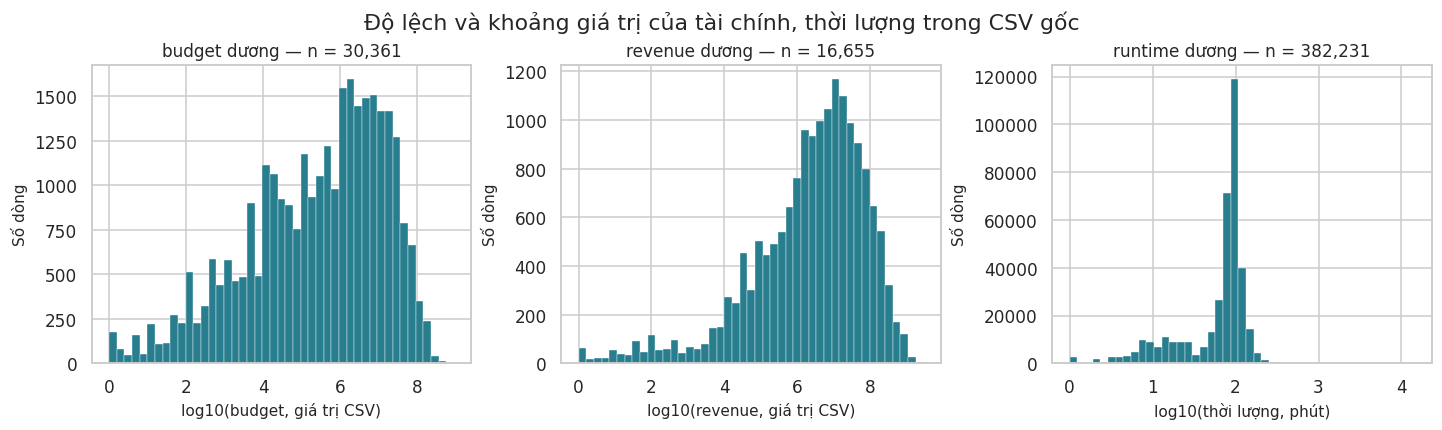

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for ax, col in zip(axes, ['budget', 'revenue', 'runtime']):
    values = movies.loc[movies[col].gt(0), col]
    ax.hist(np.log10(values), bins=45, color='#287e8e', edgecolor='white', linewidth=.25)
    ax.set(title=f'{col} dương — n = {len(values):,}',
           xlabel=f'log10({col}, giá trị CSV)' if col != 'runtime' else 'log10(thời lượng, phút)',
           ylabel='Số dòng')
fig.suptitle('Độ lệch và khoảng giá trị của tài chính, thời lượng trong CSV gốc')
plt.show()

Hình tiếp theo cho thấy điểm và lượt chấm trên từng nền tảng. Phân phối điểm dùng toàn bộ CSV, có cả điểm TMDb bằng 0. Hình lượt chấm chỉ dùng giá trị dương. Những dòng có mã lặp vẫn xuất hiện trong các hình tổng quan này. Mục 6.2 sẽ so hai nền tảng trên cùng mẫu đã loại mã lặp.

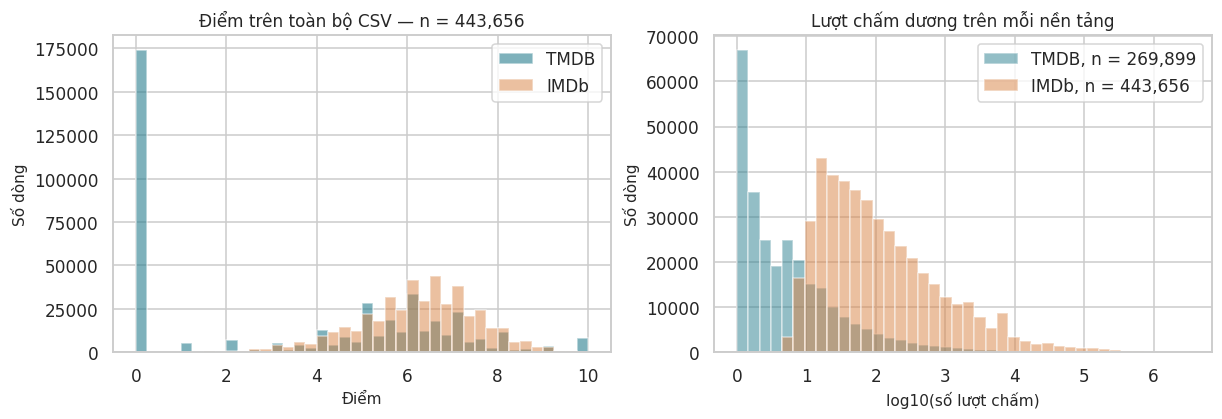

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
axes[0].hist(movies.vote_average, bins=np.linspace(0, 10, 41), alpha=.6, label='TMDB', color='#287e8e')
axes[0].hist(movies.averageRating, bins=np.linspace(0, 10, 41), alpha=.5, label='IMDb', color='#d98243')
axes[0].set(title=f'Điểm trên toàn bộ CSV — n = {n:,}', xlabel='Điểm', ylabel='Số dòng')
axes[0].legend()
vote_bins = np.linspace(0, np.log10(movies[['vote_count', 'numVotes']].max().max()), 41)
for col, label, color in [('vote_count', 'TMDB', '#287e8e'), ('numVotes', 'IMDb', '#d98243')]:
    values = movies.loc[movies[col].gt(0), col]
    axes[1].hist(np.log10(values), bins=vote_bins, alpha=.5, color=color,
                 label=f'{label}, n = {len(values):,}')
axes[1].set(title='Lượt chấm dương trên mỗi nền tảng', xlabel='log10(số lượt chấm)', ylabel='Số dòng')
axes[1].legend()
plt.show()

### 3.4. Giá trị nào nằm xa phần lớn dữ liệu?

IQR dùng khoảng 25%–75% để đặt ngưỡng kiểm tra. Z-score đo khoảng cách tới trung bình theo số độ lệch chuẩn, với ngưỡng ở đây là `|z| > 3`. Với biến tài chính, thời lượng và lượt chấm, cả hai cách dùng cùng phần giá trị dương. Điểm dùng toàn bộ giá trị có sẵn.

IQR và z-score đánh dấu giá trị cần xem thêm. Để quyết định giữ hay loại, nhóm đối chiếu nguồn và xét phạm vi của từng câu hỏi.

In [16]:
outliers = []
for col in numeric_cols:
    s = movies.loc[movies[col].gt(0), col] if col in positive_cols else movies[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_flagged = s.lt(lo) | s.gt(hi)
    z_scores = (s - s.mean()) / s.std(ddof=0)
    valid_z = z_scores.notna()
    z_flagged = z_scores.abs().gt(3)
    outliers.append([
        col, '> 0' if col in positive_cols else 'không thiếu', len(s), lo, hi,
        int(iqr_flagged.sum()), 100 * iqr_flagged.mean(), int(valid_z.sum()),
        int(z_flagged.sum()), 100 * z_flagged.loc[valid_z].mean(),
    ])

outlier_audit = pd.DataFrame(outliers, columns=[
    'cột', 'mẫu', 'n', 'ngưỡng dưới IQR', 'ngưỡng trên IQR',
    'số giá trị ngoài ngưỡng IQR', 'tỷ lệ ngoài ngưỡng IQR (%)', 'số giá trị tính được z-score', 'số giá trị có |z| > 3', 'tỷ lệ có |z| > 3 (%)',
])


display(outlier_audit[['cột', 'mẫu', 'n', 'số giá trị ngoài ngưỡng IQR',
                       'tỷ lệ ngoài ngưỡng IQR (%)', 'số giá trị có |z| > 3',
                       'tỷ lệ có |z| > 3 (%)']].round(2))

,cột,mẫu,n,số giá trị ngoài ngưỡng IQR,tỷ lệ ngoài ngưỡng IQR (%),số giá trị có |z| > 3,tỷ lệ có |z| > 3 (%)
0,budget,> 0,30361,4771,15.71,643,2.12
1,revenue,> 0,16655,2419,14.52,319,1.92
2,runtime,> 0,382231,5798,1.52,1196,0.31
3,vote_average,không thiếu,443656,0,0.00,0,0.00
4,vote_count,> 0,269899,40271,14.92,2135,0.79
5,averageRating,không thiếu,443656,5907,1.33,1932,0.44
6,numVotes,> 0,443656,71794,16.18,2739,0.62
7,popularity,> 0,425895,52031,12.22,1479,0.35


Trên phân phối lệch mạnh, giá trị rất lớn kéo trung bình và độ lệch chuẩn lên, nên z-score có thể phát hiện ít trường hợp hơn IQR. Ngưỡng số dưới đây cho phép kiểm tra trực tiếp mỗi cách tính.

In [17]:
display(outlier_audit[['cột', 'ngưỡng dưới IQR', 'ngưỡng trên IQR',
                       'số giá trị tính được z-score']].round(2))

,cột,ngưỡng dưới IQR,ngưỡng trên IQR,số giá trị tính được z-score
0,budget,-8962500.00,14977500.00,30361
1,revenue,-40667916.00,68695060.00,16655
2,runtime,-21.00,171.00,382231
3,vote_average,-9.30,15.50,443656
4,vote_count,-13.00,27.00,269899
5,averageRating,2.85,9.65,443656
6,numVotes,-474.00,854.00,443656
7,popularity,-1.05,3.34,425895


**Đối chiếu một số trường hợp với nguồn**

| Trường hợp trong CSV | Kết quả đối chiếu | Hướng xử lý |
| --- | --- | --- |
| *Modern Times Forever* ghi thời lượng **14.400 phút** | **Ngoại lệ hợp lệ.** Tác giả công bố tác phẩm dài 240 giờ, đúng bằng 14.400 phút. [SUPERFLEX](https://superflex.net/works/modern_times_forever) | Giữ nếu tác phẩm nghệ thuật này nằm trong phạm vi Q3. Một ngưỡng thời lượng cứng có thể loại cả giá trị đúng này. |
| *Tanguy, le retour* ghi thời lượng **0 phút** | **Thời lượng trong CSV sai nếu đọc là thời lượng thực.** Hồ sơ báo chí ghi 93 phút. [Hồ sơ báo chí của phim](https://medias.unifrance.org/medias/240/29/204272/presse/tanguy-le-retour-dossier-de-presse-francais.pdf) | Xem số 0 là thời lượng chưa dùng được theo mục 3.2. |
| *Red Dead Redemption 2 (Movie)* đi với mã IMDb `tt6161168` | **Liên kết khác loại tác phẩm.** Mã IMDb trỏ đến trò chơi *Red Dead Redemption II*. [IMDb](https://www.imdb.com/title/tt6161168/) · [Rockstar Games](https://www.rockstargames.com/newswire/article/75o941131a99k5/Red-Dead-Redemption-2-Now-Available-for-PC) | Rà lại liên kết trước khi dùng các trường ghép để phân tích phim. |
| *Unsubscribe* (2020), `tt12519206`, ghi ngân sách **0** | **Khớp ngân sách sản xuất tự khai.** Hồ sơ do ê-kíp đăng ghi 0 USD cho phần sản xuất phim. [FilmFreeway](https://filmfreeway.com/Unsubscribe_short) | Ghi nhận trường hợp ngân sách sản xuất bằng 0 đã đối chiếu. |
| *Colin* (2008), `tt1278322`, cũng ghi ngân sách **0** | **Sai lệch với chi phí được báo cáo.** Đạo diễn Marc Price cho biết chi phí làm phim khoảng 45 GBP. [Phỏng vấn Marc Price](https://chrisjonesblog.com/2009/12/marc-price-director-of-colin-talks-to-the-guerilla-film-makers-pocketbook.html) | Xem ngân sách trong CSV là chưa dùng được cho phân tích tài chính. |
| *Hush* của Mark Tonderai, `tt1093369`, ghi ngân sách **1** | **Giá trị CSV không phản ánh quy mô sản xuất.** Báo cáo về UK Film Council ghi riêng khoản tài trợ từ New Cinema Fund là 299.983 GBP. Khoản tài trợ này chỉ là một phần thông tin tài chính của phim. [Báo cáo lưu tại BFI](https://www2.bfi.org.uk/sites/bfi.org.uk/files/downloads/uk-film-council-talent-development-review.pdf) | Đánh dấu ngân sách 1 là nhiễu trong trường hợp này. |
| *Primer* (2004) ghi ngân sách **7.000** | **Ngân sách rất thấp có căn cứ.** Sundance Institute ghi ngân sách 7.000 USD. [Sundance Institute](https://www.sundance.org/blogs/5-of-the-lowest-budget-sundance-films-ever-made-3/) | Giữ trường hợp này khi khảo sát phim ngân sách thấp. |
| *The Blair Witch Project* (1999) ghi ngân sách **60.000** và doanh thu **248.639.099** | **Cả hai giá trị khớp nguồn đối chiếu.** Box Office Mojo ghi ngân sách 60.000 USD và doanh thu phòng vé toàn cầu 248.639.099 USD cho đợt phát hành gốc. [Box Office Mojo](https://www.boxofficemojo.com/title/tt0185937/) | Giữ cả hai giá trị. Doanh thu rất cao so với ngân sách có thể xảy ra ở từng phim. |
| *Enea* (2023) ghi ngân sách **888.000.000** | **Ngân sách có dấu hiệu nhiễu.** ANSA đưa mức 8,2 triệu EUR, còn Box Office Biz ghi 8,4 triệu EUR. Đơn vị của giá trị trong CSV chưa được xác minh. [ANSA](https://www.ansa.it/amp/sito/notizie/cultura/cinema/2023/08/27/venezia-rilancia-il-cinema-italiano-merito-e-budget_89b00ad3-f80f-48b5-a777-f78683fee9ea.html) · [Box Office Biz](https://boxofficebiz.it/news/cinema-italiano-alto-budget-alto-incasso/) | Đánh dấu để xác minh nguồn và đơn vị trước khi dùng ngân sách này trong phân tích. |
| *A Ticket to Space* (2006) ghi doanh thu **2** | **Giá trị CSV không dùng được làm doanh thu phòng vé.** Box Office Mojo ghi 2.674.500 USD tại Pháp. [Box Office Mojo](https://www.boxofficemojo.com/title/tt0444519/) | Xem đây là trường hợp nhiễu khi đối chiếu doanh thu phòng vé. |

Hai phim cùng có ngân sách 0 trong CSV cho thấy cần đối chiếu từng tác phẩm. Ngân sách sản xuất phản ánh chi phí làm phim, còn việc khán giả có phải trả tiền để xem là vấn đề phát hành. Trong các trường hợp đã rà, nhóm chưa tìm thấy ví dụ ngân sách đúng bằng 1 được nguồn sản xuất xác nhận.

**Cách nhóm dự kiến xử lý ở bước phân tích**

- **Dưới 10 tác phẩm cần rà trong mẫu của câu hỏi.** Đối chiếu từng trường hợp. Giữ thủ công các giá trị đã xác minh và phù hợp phạm vi, rồi loại những trường hợp đã xác định là nhiễu. Ghi lại mã tác phẩm, nguồn và lý do cho quyết định.
- **Từ 10 tác phẩm trở lên.** Nếu đối chiếu cho thấy nhóm bị đánh dấu có nhiều dữ liệu nhiễu và khó rà từng trường hợp, nhóm có thể dùng một ngưỡng phù hợp với câu hỏi. Khi đó, chấp nhận khả năng mất một số quan sát hợp lệ và ghi rõ sự đánh đổi này.
- **Kiểm tra độ nhạy.** Báo số tác phẩm trước và sau lọc, rồi so kết quả trên hai mẫu để xem kết luận thay đổi bao nhiêu. Các bảng ở notebook khám phá dùng ngưỡng IQR và z-score để mô tả.

## 4. Cột phân loại, thể loại và ngày phát hành

Cột phân loại chia tác phẩm thành nhóm, chẳng hạn ngôn ngữ gốc hay trạng thái phát hành. Cột `genres` có thể chứa nhiều thể loại trên cùng một dòng.

### 4.1. Trạng thái phát hành và ngôn ngữ gốc

`Released` nghĩa là đã phát hành theo dữ liệu nguồn. Các trạng thái khác gồm đang hậu kỳ, đang sản xuất, lên kế hoạch, bị hủy và mới có tin đồn. Ngày ghi trong CSV và trạng thái đôi khi chưa nhất quán, nên hai cột cần đọc cùng nhau.

In [18]:
status_meanings = {'Released': 'Đã phát hành', 'Post Production': 'Đang hậu kỳ',
    'In Production': 'Đang sản xuất', 'Planned': 'Đang lên kế hoạch',
    'Canceled': 'Đã hủy', 'Rumored': 'Mới có tin đồn'}
status_counts = movies.status.value_counts()
display(pd.DataFrame({'Ý nghĩa': status_counts.index.map(status_meanings),
    'Số dòng': status_counts, 'Tỷ lệ (%)': 100 * status_counts / n}).round(2))

,Ý nghĩa,Số dòng,Tỷ lệ (%)
status,,,
Released,Đã phát hành,440762,99.35
Post Production,Đang hậu kỳ,1676,0.38
In Production,Đang sản xuất,1043,0.24
Planned,Đang lên kế hoạch,161,0.04
Canceled,Đã hủy,9,0.00
Rumored,Mới có tin đồn,5,0.00


Bảng ngôn ngữ liệt kê 15 nhóm nhiều dòng nhất. Mã `en` là tiếng Anh, `fr` là tiếng Pháp, `es` là tiếng Tây Ban Nha và `ja` là tiếng Nhật. Một nhóm nhiều dữ liệu có thể chi phối kết quả chung.

In [19]:
language_counts_raw = movies.original_language.value_counts()
display(pd.DataFrame({'Số dòng': language_counts_raw.head(15),
    'Tỷ lệ trong CSV (%)': 100 * language_counts_raw.head(15) / n}).round(2))
category_audit = []
for column in ['original_language', 'status', 'adult']:
    counts = movies.loc[~missing[column], column].value_counts()
    category_audit.append([column, len(counts), int(counts.le(5).sum()),
        int(counts.loc[counts.le(5)].sum()), int(missing[column].sum())])
display(pd.DataFrame(category_audit, columns=['Cột', 'Số nhãn khác nhau',
    'Số nhãn có tối đa 5 dòng', 'Số dòng thuộc nhãn ít gặp', 'Số dòng thiếu']))

,Số dòng,Tỷ lệ trong CSV (%)
original_language,,
en,242967,54.76
fr,24927,5.62
es,21908,4.94
de,21843,4.92
ja,13285,2.99
it,11978,2.70
ru,9472,2.13
pt,8287,1.87
zh,6907,1.56


,Cột,Số nhãn khác nhau,Số nhãn có tối đa 5 dòng,Số dòng thuộc nhãn ít gặp,Số dòng thiếu
0,original_language,158,38,79,0
1,status,6,1,5,0
2,adult,2,0,0,0


Các nhóm có tối đa 5 dòng được liệt kê để xem độ thưa dữ liệu. Khi so sánh Q3, ưu tiên các ngôn ngữ có đủ phim trong từng giai đoạn và báo số phim. Với Q2, cách gom nhãn hiếm phải được học trên tập huấn luyện.

Bảng kiểm tra cách viết tìm dấu cách thừa và nhãn khác nhau chỉ vì chữ hoa/chữ thường. Mã có đúng dạng hai chữ thường vẫn cần được đọc theo quy ước của TMDb.

In [20]:
display(language_counts_raw.loc[language_counts_raw.le(5)].head(20).to_frame('Ví dụ ngôn ngữ có tối đa 5 dòng'))
label_checks = []
for column in ['original_language', 'status']:
    values = movies.loc[~missing[column], column]
    pairs = pd.DataFrame({'gốc': values, 'chuẩn': values.str.strip().str.casefold()}).drop_duplicates()
    collisions = pairs.groupby('chuẩn')['gốc'].nunique()
    label_checks.append([column, int(values.ne(values.str.strip()).sum()), int(collisions.gt(1).sum())])
display(pd.DataFrame(label_checks, columns=['Cột', 'Dòng có dấu cách thừa', 'Nhãn có nhiều cách viết']))

,Ví dụ ngôn ngữ có tối đa 5 dòng
original_language,
fy,5
cr,4
ce,4
sm,4
tt,4
gn,4
lg,3
ny,3
ti,3


,Cột,Dòng có dấu cách thừa,Nhãn có nhiều cách viết
0,original_language,0,0
1,status,0,0


### 4.2. Một dòng có bao nhiêu thể loại khác nhau?

Đếm nhãn khác nhau sau khi tách danh sách. Ví dụ, `Animation, Animation` có **một** thể loại khác nhau và đồng thời được ghi nhận là có nhãn lặp. Việc này sửa lỗi đếm nhiều thể loại ở bản trước.

In [21]:
raw_genre_lists = movies.genres.fillna('').str.split(',').map(
    lambda parts: [part.strip() for part in parts if part.strip()])
genre_duplicate_tokens = raw_genre_lists.map(lambda parts: len(parts) != len(set(parts)))
genre_lists = raw_genre_lists.map(lambda parts: sorted(set(parts)))
genre_count = genre_lists.map(len)
genre_brackets = movies.genres.fillna('').str.contains(r'[\[\]{}]', regex=True)
genre_audit = pd.Series({
    'Dòng thiếu thể loại': int(missing.genres.sum()),
    'Dòng có ít nhất hai thể loại khác nhau': int(genre_count.gt(1).sum()),
    'Dòng lặp nhãn thể loại': int(genre_duplicate_tokens.sum()),
    'Dòng có dấu ngoặc cần xem cách tách': int(genre_brackets.sum()),
    'Số thể loại khác nhau nhiều nhất trong một dòng': int(genre_count.max()),
})
display(genre_audit.to_frame('Kết quả'))
display(movies.loc[genre_duplicate_tokens, ['title', 'genres']].head(3))

,Kết quả
Dòng thiếu thể loại,83813
Dòng có ít nhất hai thể loại khác nhau,171180
Dòng lặp nhãn thể loại,95
Dòng có dấu ngoặc cần xem cách tách,0
Số thể loại khác nhau nhiều nhất trong một dòng,11


,title,genres
68737,Ded Moroz and the Grey Wolf,"Animation, Animation"
72418,Hayat Sevince Güzel,"Comedy, Family, Drama, Romance, Family, Comedy..."
73013,Deadly Hero,"Drama, Thriller, Crime, Drama"


Bảng tiếp theo đếm mỗi thể loại tối đa một lần trên một dòng. Một tác phẩm thuộc hai thể loại sẽ góp mặt trong hai hàng, nên tổng tỷ lệ thể loại có thể vượt 100%. Khi phân tích tài chính, cần giữ mã tác phẩm để kiểm soát việc đếm lặp.

In [22]:
genre_tokens = genre_lists.explode().dropna()
genre_counts = genre_tokens.value_counts()
display(pd.DataFrame({'Số dòng có thể loại': genre_counts,
    'Tỷ lệ trong CSV (%)': 100 * genre_counts / n}).round(2))
display(genre_count.value_counts().sort_index().rename_axis('Số thể loại khác nhau')
        .to_frame('Số dòng'))

,Số dòng có thể loại,Tỷ lệ trong CSV (%)
genres,,
Drama,140009,31.56
Comedy,92583,20.87
Documentary,59518,13.42
Romance,35904,8.09
Thriller,33768,7.61
Action,32986,7.44
Horror,31615,7.13
Animation,26322,5.93
Crime,25105,5.66


,Số dòng
Số thể loại khác nhau,
0,83813
1,188663
2,108484
3,47949
4,11434
5,2569
6,626
7,94
8,18


### 4.3. Ngày phát hành có đọc được và hợp lý không?

Bảng kiểm tra ngày viết sai dạng, ngày đọc không được, và ngày sau **05/11/2026**, là ngày nhóm tải CSV. Một lịch phát hành tương lai có thể hợp lệ với tác phẩm đang sản xuất. Nhãn `Released` kèm ngày tương lai cần được đối chiếu riêng.

In [23]:
release_dates = pd.to_datetime(movies.release_date, format='%Y-%m-%d', errors='coerce')
release_years = release_dates.dt.year
invalid_dates = ~missing.release_date & release_dates.isna()
non_iso = ~missing.release_date & ~movies.release_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
date_audit = pd.Series({'thiếu release_date': int(missing.release_date.sum()),
    'có ghi ngày nhưng không đọc được': int(invalid_dates.sum()),
    'ngày viết sai dạng năm-tháng-ngày': int(non_iso.sum()),
    'ngày sớm nhất': str(release_dates.min().date()),
    'ngày muộn nhất': str(release_dates.max().date()),
    'sau ngày nhóm tải 05/11/2026': int(release_dates.gt(DOWNLOAD_DATE).sum()),
    'Released nhưng ngày sau ngày tải': int((release_dates.gt(DOWNLOAD_DATE) & movies.status.eq('Released')).sum())})
display(date_audit.to_frame('Kết quả'))
display(movies.loc[invalid_dates | non_iso | release_dates.gt(DOWNLOAD_DATE),
                   ['id', 'tconst', 'title', 'release_date', 'status']].head(15))

,Kết quả
thiếu release_date,25363
có ghi ngày nhưng không đọc được,0
ngày viết sai dạng năm-tháng-ngày,0
ngày sớm nhất,1874-12-09
ngày muộn nhất,2029-10-13
sau ngày nhóm tải 05/11/2026,3
Released nhưng ngày sau ngày tải,2


,id,tconst,title,release_date,status
272007,1225835,tt8270746,শূন্যতা,2027-04-21,Released
286448,1355413,tt5835938,Pela Adhi Akshar,2027-03-24,In Production
287509,1227249,tt10333734,Indiana Jones: Return of Elsa Schneider,2029-10-13,Released


Các ngày có giá trị đều đọc được, nhưng có 3 dòng mang ngày sau ngày tải, trong đó 2 dòng ghi `Released`. Khoảng ngày 1874–2029 là khoảng ngày phát hành ghi trong CSV. Thời điểm lấy điểm và lượt chấm từ mỗi nguồn chưa được xác nhận.

Bảng dưới cho biết số dòng theo thời gian trước và sau khi chọn hai mã chỉ xuất hiện một lần. Mục 6 sẽ áp dụng thêm trạng thái và điều kiện riêng từng câu.

In [24]:
period_labels = ['1990–1999', '2000–2009', '2010–2019', '2020–2024']
raw_periods = pd.cut(release_years, bins=[1989, 1999, 2009, 2019, 2024], labels=period_labels)
coverage_1990_2024 = pd.DataFrame({
    'số dòng trong CSV gốc': raw_periods.value_counts(sort=False),
    'số dòng có cả hai mã chỉ xuất hiện một lần': raw_periods.loc[unique_keys].value_counts(sort=False),
})
display(coverage_1990_2024)
display(pd.Series({
    'thiếu hoặc không đọc được ngày': int(release_dates.isna().sum()),
    'trước 1990': int(release_years.lt(1990).sum()),
    '1990–2024': int(release_years.between(1990, 2024).sum()),
    'sau 2024': int(release_years.gt(2024).sum()),
}, name='Số dòng theo năm phát hành trong CSV gốc'))

,số dòng trong CSV gốc,số dòng có cả hai mã chỉ xuất hiện một lần
release_date,,
1990–1999,39120,38788
2000–2009,69832,68860
2010–2019,123528,121025
2020–2024,50388,45267


thiếu hoặc không đọc được ngày     25363
trước 1990                        135411
1990–2024                         282868
sau 2024                              14
Name: Số dòng theo năm phát hành trong CSV gốc, dtype: int64

## 5. Dữ liệu thiếu và cách xử lý dự kiến

### 5.1. Cột nào thiếu nhiều?

Ô trống, ký hiệu IMDb `\N` và ô chỉ có dấu cách đều được tính là thiếu. Các giá trị 0 đã ghi trong ba cột ngân sách, doanh thu và thời lượng được đếm riêng ở mục 3.2. Tỷ lệ ở đây dùng **443.656 dòng** của toàn bộ CSV làm mẫu số.

In [25]:
missing_table = pd.DataFrame({
    'số giá trị được đọc là thiếu': movies.isna().sum(),
    'số ô chỉ có dấu cách': space_only,
    'số thiếu': missing.sum(),
    'tỷ lệ thiếu (%)': 100 * missing.mean(),
}).sort_values('số thiếu', ascending=False)
display(missing_table[['số thiếu', 'tỷ lệ thiếu (%)']].round(2))

,số thiếu,tỷ lệ thiếu (%)
homepage,387892,87.43
tagline,349641,78.81
keywords,272009,61.31
backdrop_path,256638,57.85
production_companies,180269,40.63
production_countries,121880,27.47
spoken_languages,109772,24.74
genres,83813,18.89
poster_path,79371,17.89
cast,69646,15.70


Có ô chứa chữ nhưng thực chất chỉ là dấu cách. Bảng nhỏ này cho biết những cột phát sinh thêm giá trị thiếu khi kiểm tra dấu cách, để người đọc hiểu vì sao số thiếu có thể cao hơn kết quả đọc CSV ban đầu.

In [26]:
display(missing_table.loc[space_only.gt(0),
        ['số giá trị được đọc là thiếu', 'số ô chỉ có dấu cách', 'số thiếu']])

,số giá trị được đọc là thiếu,số ô chỉ có dấu cách,số thiếu
homepage,387889,3,387892
overview,44974,64,45038


Trong các cột dùng cho bốn câu hỏi, ngày phát hành và thể loại có ô thiếu. Các cột số có 0% ô thiếu vẫn cần kiểm tra số 0 và các giá trị đáng nghi đã nêu ở mục 3.

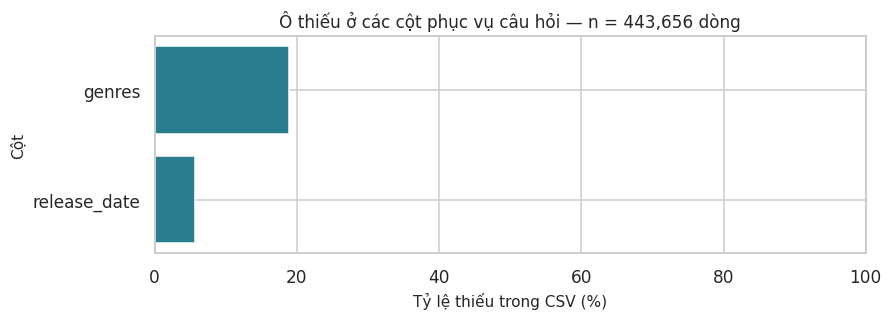

In [27]:
important = ['release_date', 'genres', 'original_language', 'runtime', 'budget', 'revenue',
             'vote_average', 'vote_count', 'averageRating', 'numVotes']
shown = missing_table.loc[important].query('`số thiếu` > 0').sort_values('tỷ lệ thiếu (%)')
fig, ax = plt.subplots(figsize=(8, 2.8), layout='constrained')
ax.barh(shown.index, shown['tỷ lệ thiếu (%)'], color='#287e8e')
ax.set(xlabel='Tỷ lệ thiếu trong CSV (%)', ylabel='Cột', xlim=(0, 100),
       title=f'Ô thiếu ở các cột phục vụ câu hỏi — n = {n:,} dòng')
plt.show()

### 5.2. Các cột có thường thiếu cùng nhau không?

Mỗi hàng dưới là một tổ hợp có hoặc thiếu dữ liệu. `Có` trong cột `Thiếu ngày` nghĩa là dòng đó thiếu ngày phát hành. Bảng giúp xem việc lọc một cột có đồng thời loại nhiều dòng thiếu cột khác hay không.

In [28]:
pattern_columns = ['release_date', 'genres', 'original_language']
patterns = missing[pattern_columns].value_counts().rename('Số dòng').reset_index()
patterns['Tỷ lệ trong CSV (%)'] = 100 * patterns['Số dòng'] / n
pattern_view = patterns.rename(columns={'release_date': 'Thiếu ngày',
    'genres': 'Thiếu thể loại', 'original_language': 'Thiếu ngôn ngữ'})
for column in ['Thiếu ngày', 'Thiếu thể loại', 'Thiếu ngôn ngữ']:
    pattern_view[column] = pattern_view[column].map({True: 'Có', False: 'Không'})
display(pattern_view.round(2))
joint_missing = int((missing.release_date & missing.genres).sum())
display(Markdown(f'Có **{joint_missing:,} dòng** thiếu cả ngày và thể loại, chiếm '
    f'**{joint_missing / missing.release_date.sum():.2%}** các dòng thiếu ngày phát hành.'))

,Thiếu ngày,Thiếu thể loại,Thiếu ngôn ngữ,Số dòng,Tỷ lệ trong CSV (%)
0,Không,Không,Không,354549,79.92
1,Không,Có,Không,63744,14.37
2,Có,Có,Không,20069,4.52
3,Có,Không,Không,5294,1.19


Có **20,069 dòng** thiếu cả ngày và thể loại, chiếm **79.13%** các dòng thiếu ngày phát hành.

### 5.3. Việc thiếu dữ liệu khác nhau giữa các nhóm ra sao?

Trong các bảng tiếp theo, mỗi phần trăm dùng **số dòng của chính hàng đó** làm mẫu số. Chẳng hạn, tỷ lệ thiếu ngày của nhóm `Planned` được tính trong các dòng `Planned`. Các cột bằng 0 vẫn được ghi riêng để theo dõi tình trạng dữ liệu.

In [29]:
availability = missing[pattern_columns].rename(columns=lambda col: 'thiếu_' + col).copy()
availability['budget_bằng_0'] = movies.budget.eq(0)
availability['revenue_bằng_0'] = movies.revenue.eq(0)
availability['runtime_bằng_0'] = movies.runtime.eq(0)
availability['TMDB_không_lượt_chấm'] = movies.vote_count.eq(0)

def missing_by_group(groups):
    result = availability.groupby(groups, observed=True, dropna=False).mean().mul(100)
    result.insert(0, 'Số dòng', groups.value_counts(dropna=False))
    return result.rename(columns={
        'thiếu_release_date': 'Thiếu ngày (%)', 'thiếu_genres': 'Thiếu thể loại (%)',
        'thiếu_original_language': 'Thiếu ngôn ngữ (%)', 'budget_bằng_0': 'Ngân sách 0 (%)',
        'revenue_bằng_0': 'Doanh thu 0 (%)', 'runtime_bằng_0': 'Thời lượng 0 (%)',
        'TMDB_không_lượt_chấm': 'TMDb chưa có lượt (%)'}).round(2)

display(missing_by_group(movies.status).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
status,,,,,,,
Canceled,9,88.89,33.33,88.89,100.00,66.67,100.00
In Production,1043,37.20,16.30,92.71,99.90,68.46,100.00
Planned,161,70.19,14.91,91.93,100.00,84.47,100.00
Post Production,1676,57.10,12.77,92.30,100.00,64.32,99.88
Released,440762,5.42,18.92,93.16,96.22,13.50,38.77
Rumored,5,100.00,20.00,100.00,100.00,80.00,80.00


Ngày phát hành thiếu ở **5,42%** nhóm `Released` và **70,19%** nhóm `Planned`. Trạng thái vì vậy liên quan đến khả năng có ngày trong CSV. Những con số này mô tả mẫu hình, còn nguyên nhân thiếu của từng dòng cần nguồn đối chiếu.

Bảng ngôn ngữ dưới giữ 10 nhóm đông nhất và gom các nhóm còn lại cho lần xem tổng quan này.

In [30]:
top_languages = movies.original_language.value_counts().head(10).index
language_groups = movies.original_language.where(
    movies.original_language.isin(top_languages), 'Các ngôn ngữ còn lại')
display(missing_by_group(language_groups).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
original_language,,,,,,,
Các ngôn ngữ còn lại,76007,2.70,11.90,95.69,97.39,17.86,40.20
de,21843,2.92,11.93,97.83,98.82,36.86,42.74
en,242967,8.07,23.41,90.76,95.42,9.10,41.87
es,21908,4.10,19.34,95.79,97.04,21.28,27.30
fr,24927,2.88,16.62,95.92,97.50,15.11,29.79
hi,6075,1.89,18.40,92.16,93.28,18.85,36.89
it,11978,3.34,13.81,96.72,97.65,22.82,27.84
ja,13285,0.78,10.52,98.07,96.50,3.20,25.98
pt,8287,3.21,13.50,96.11,98.66,21.30,42.51


Bảng theo thập niên giúp xem các tác phẩm ở giai đoạn khác nhau có mức đầy đủ tài chính và thời lượng khác nhau không. Dòng thiếu ngày được giữ thành một nhóm riêng.

In [31]:
decades = ((release_years // 10) * 10).astype('Int64').astype('string').fillna('Thiếu hoặc không đọc được ngày')
display(missing_by_group(decades).drop(columns='Thiếu ngôn ngữ (%)'))

,Số dòng,Thiếu ngày (%),Thiếu thể loại (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%),TMDb chưa có lượt (%)
release_date,,,,,,,
1870,19,0.0,15.79,94.74,100.00,15.79,57.89
1880,33,0.0,21.21,93.94,100.00,21.21,69.70
1890,1058,0.0,33.74,100.00,100.00,2.65,8.13
1900,2035,0.0,38.67,99.66,100.00,2.21,20.84
1910,4024,0.0,21.32,99.20,99.55,10.16,36.98
1920,5638,0.0,14.19,98.19,98.81,15.68,47.87
1930,12763,0.0,9.23,97.79,99.00,9.44,38.54
1940,11897,0.0,7.81,97.81,98.44,7.14,33.81
1950,15495,0.0,10.93,97.71,98.30,12.80,33.31


Bảng theo thể loại cho biết khả năng có thông tin phục vụ Q3 và Q4. Một dòng có nhiều thể loại góp mặt trong nhiều hàng. Mỗi tỷ lệ vẫn dùng số dòng của thể loại đó làm mẫu số.

In [32]:
genre_quality = availability[['thiếu_release_date', 'budget_bằng_0', 'revenue_bằng_0', 'runtime_bằng_0']].copy()
genre_quality['genre'] = genre_lists
genre_quality = genre_quality.explode('genre').dropna(subset=['genre'])
genre_availability = genre_quality.groupby('genre').mean().mul(100)
genre_availability.insert(0, 'Số dòng', genre_quality.groupby('genre').size())
display(genre_availability.rename(columns={'thiếu_release_date': 'Thiếu ngày (%)',
    'budget_bằng_0': 'Ngân sách 0 (%)', 'revenue_bằng_0': 'Doanh thu 0 (%)',
    'runtime_bằng_0': 'Thời lượng 0 (%)'}).sort_values('Số dòng', ascending=False).head(10).round(2))

,Số dòng,Thiếu ngày (%),Ngân sách 0 (%),Doanh thu 0 (%),Thời lượng 0 (%)
genre,,,,,
Drama,140009,1.08,91.82,94.53,9.78
Comedy,92583,1.49,91.36,93.85,12.06
Documentary,59518,1.68,96.35,98.96,8.25
Romance,35904,0.98,90.60,91.75,8.71
Thriller,33768,1.99,83.46,89.98,7.30
Action,32986,2.34,85.57,89.75,10.17
Horror,31615,2.92,83.14,94.10,6.39
Animation,26322,1.31,95.62,95.75,5.07
Crime,25105,1.23,88.56,91.58,9.21


## 6. Mối liên hệ sơ bộ giữa các thuộc tính

Mỗi biểu đồ hoặc bảng dưới đây dùng một mẫu phù hợp với các thuộc tính đang xét. Khảo sát này dùng để nhận diện mẫu hình và giới hạn dữ liệu trước khi phân tích từng câu hỏi.

Bốn câu hỏi của nhóm gồm:

- **Q1.** IMDb và TMDb chấm điểm lệch nhau như thế nào?
- **Q2.** Nhìn hồ sơ phim, đoán khán giả IMDb chấm mấy điểm?
- **Q3.** Phim có ngày càng dài hơn không?
- **Q4.** Cùng mức ngân sách, thể loại phim nào thường có doanh thu cao hơn?

### 6.1. Phạm vi các mẫu khám phá

Cả bốn mẫu đều yêu cầu `id` và `tconst` có giá trị, mỗi mã chỉ xuất hiện đúng một lần trong CSV gốc. Điều kiện `status = 'Released'` chỉ giữ các dòng có trạng thái đã phát hành. Cột `release_date` phải đọc được để kiểm tra năm. Q1 và Q2 lấy đến hết 2025, không đặt mốc năm bắt đầu. Q3 và Q4 dùng năm để chia giai đoạn.

Trong bảng, thang điểm và khoảng năm tính cả hai đầu mút. Điều kiện có thể loại nghĩa là `genres` còn ít nhất một nhãn sau khi tách và bỏ nhãn rỗng.

In [33]:
analysis_base = movies.loc[unique_keys, focus_columns + ['title']].copy()
analysis_base['release_year'] = release_years.loc[analysis_base.index]
analysis_base['period'] = raw_periods.loc[analysis_base.index]
analysis_base['genre_list'] = genre_lists.loc[analysis_base.index]
has_genre = genre_count.gt(0)
year_1990_2024 = release_years.between(1990, 2024)
year_through_2025 = release_years.le(2025)
released = movies.status.eq('Released')
valid_imdb = movies.averageRating.between(1, 10) & movies.numVotes.gt(0)
valid_pair = movies.vote_average.between(0, 10) & valid_imdb & movies.vote_count.gt(0)
question_steps = {
    'Q1': [('Trạng thái Released', released), ('Có ngày phát hành đọc được và năm ≤ 2025', year_through_2025),
           ('Hai điểm trong thang và có lượt chấm ở cả hai bên', valid_pair),
           ('Ít nhất 10 lượt ở mỗi nền tảng', movies.vote_count.ge(10) & movies.numVotes.ge(10))],
    'Q2': [('Trạng thái Released', released),
           ('Có ngày phát hành đọc được và năm ≤ 2025', year_through_2025),
           ('Có điểm IMDb từ 1 đến 10 và có lượt', valid_imdb)],
    'Q3': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Thời lượng dương', movies.runtime.gt(0)), ('Có thể loại', has_genre)],
    'Q4': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Ngân sách dương', movies.budget.gt(0)), ('Doanh thu dương', movies.revenue.gt(0)),
           ('Có thể loại', has_genre)],
}

In [34]:
flow_rows = []
question_masks = {}
for question, steps in question_steps.items():
    selected = unique_keys.copy()
    flow_rows.append([question, 'Bắt đầu từ hai mã chỉ xuất hiện một lần', int(selected.sum()), 0])
    for label, condition in steps:
        before = int(selected.sum())
        selected &= condition
        after = int(selected.sum())
        flow_rows.append([question, label, after, before - after])
    question_masks[question] = selected
sample_flow = pd.DataFrame(flow_rows, columns=['câu', 'điều kiện thêm vào', 'số dòng còn lại', 'loại ở bước này'])
question_frames = {question: analysis_base.loc[mask.loc[analysis_base.index]].copy()
                   for question, mask in question_masks.items()}
question_sizes = pd.Series({question: len(frame) for question, frame in question_frames.items()}, name='Số dòng dữ liệu')
sample_overview = question_sizes.to_frame()
sample_overview['status'] = 'Released'
sample_overview['Năm từ release_date'] = [
    'Có ngày, năm ≤ 2025', 'Có ngày, năm ≤ 2025',
    '1990–2024', '1990–2024',
]
sample_overview['Điều kiện trên các cột'] = [
    '0 ≤ vote_average ≤ 10, 1 ≤ averageRating ≤ 10, vote_count ≥ 10, numVotes ≥ 10',
    '1 ≤ averageRating ≤ 10, numVotes > 0',
    'runtime > 0 và genres có ít nhất một nhãn',
    'budget > 0, revenue > 0 và genres có ít nhất một nhãn',
]
with pd.option_context('display.max_colwidth', None):
    display(sample_overview.rename_axis('Mẫu'))

,Số dòng dữ liệu,status,Năm từ release_date,Điều kiện trên các cột
Mẫu,,,,
Q1,77674,Released,"Có ngày, năm ≤ 2025","0 ≤ vote_average ≤ 10, 1 ≤ averageRating ≤ 10, vote_count ≥ 10, numVotes ≥ 10"
Q2,407278,Released,"Có ngày, năm ≤ 2025","1 ≤ averageRating ≤ 10, numVotes > 0"
Q3,209322,Released,1990–2024,runtime > 0 và genres có ít nhất một nhãn
Q4,8049,Released,1990–2024,"budget > 0, revenue > 0 và genres có ít nhất một nhãn"


### 6.2. Mối liên hệ giữa điểm IMDb và TMDb

Bảng cho biết số cặp điểm theo ngưỡng lượt chấm ở cả hai nền tảng, trong phạm vi Q1 ở mục 6.1. Hình dùng mẫu có ít nhất 10 lượt mỗi bên. Đường chéo đánh dấu hai điểm bằng nhau, còn màu cho biết mật độ các dòng dữ liệu quanh mỗi cặp điểm.

In [35]:
paired_ratings = analysis_base.loc[(released & year_through_2025 & valid_pair).loc[analysis_base.index]]
min_pair_votes = paired_ratings[['vote_count', 'numVotes']].min(axis=1)
rating_coverage = pd.Series(
    {threshold: int(min_pair_votes.ge(threshold).sum()) for threshold in (1, 10, 100)},
    name='Số dòng dữ liệu',
).rename_axis('Lượt chấm tối thiểu ở cả IMDb và TMDB')
display(rating_coverage.to_frame())
q1 = question_frames['Q1']

,Số dòng dữ liệu
Lượt chấm tối thiểu ở cả IMDb và TMDB,
1,265820
10,77674
100,18056


Khi nâng ngưỡng từ 10 lên 100 lượt ở mỗi nền tảng, số dòng giảm từ 77.674 xuống 18.056.

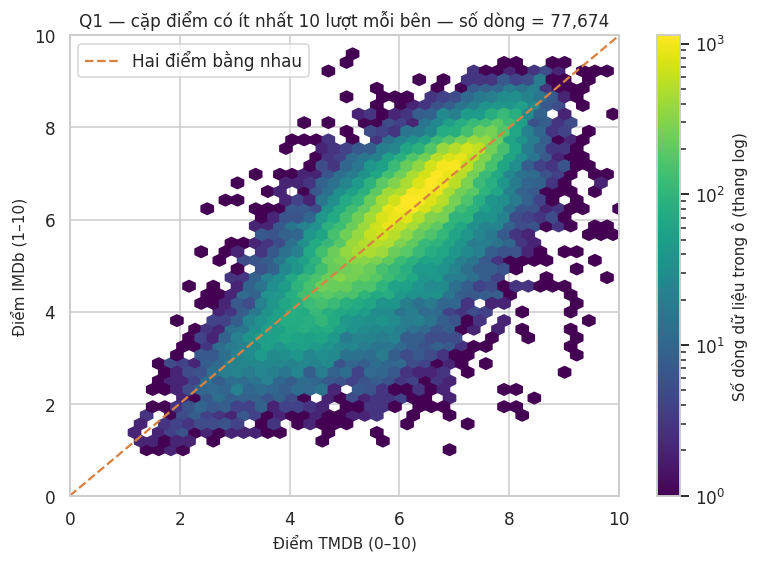

In [36]:
fig, ax = plt.subplots(figsize=(6.8, 5), layout='constrained')
hb = ax.hexbin(q1.vote_average, q1.averageRating, gridsize=40, mincnt=1, bins='log', cmap='viridis')
ax.plot([0, 10], [0, 10], '--', color='#d98243', label='Hai điểm bằng nhau')
ax.set(title=f'Q1 — cặp điểm có ít nhất 10 lượt mỗi bên — số dòng = {len(q1):,}',
       xlabel='Điểm TMDB (0–10)', ylabel='Điểm IMDb (1–10)', xlim=(0, 10), ylim=(0, 10))
ax.legend(loc='upper left')
fig.colorbar(hb, ax=ax, label='Số dòng dữ liệu trong ô (thang log)')
plt.show()

Các cặp điểm tập trung quanh đường chéo, dày nhất ở khoảng 6–7 điểm. Hai nền tảng thường cho điểm cùng chiều, nhưng ở cùng một điểm TMDB vẫn có nhiều mức điểm IMDb.

### 6.3. Điểm IMDb và các thuộc tính đầu vào của Q2

Q2 dùng các dòng trước 2020 để phát triển mô hình và dành các dòng từ 2020 đến hết 2025 làm tập kiểm tra cuối. Tỷ lệ trong bảng tính trên toàn bộ mẫu Q2. Bảng đầu ghi khoảng năm dùng để chia tập và hai mốc năm quan sát được. Bảng tiếp theo đếm số dòng của từng năm trong khoảng kiểm tra.

Mỗi lượt kiểm định chéo theo thời gian sẽ huấn luyện trên các năm sớm hơn và dùng một khoảng năm kế tiếp để validation. Phần validation nằm trong dữ liệu trước 2020 và tỷ lệ của nó thay đổi theo từng lượt chia. Sau khi chọn mô hình, nhóm huấn luyện lại trên toàn bộ phần trước 2020 rồi đánh giá trên tập kiểm tra.

Các hình khảo sát bốn thuộc tính dự kiến đưa vào mô hình, dùng dữ liệu trước 2020. Hình thời lượng chỉ dùng các dòng có thời lượng dương để lấy log10.

In [37]:
ml_scope = question_frames['Q2']
test_years = pd.RangeIndex(2020, 2026, name='Năm phát hành')
ml_train = ml_scope.loc[ml_scope.release_year.lt(2020)].copy()
ml_test = ml_scope.loc[ml_scope.release_year.isin(test_years)].copy()

ml_split_summary = pd.DataFrame({
    label: {
        'Khoảng năm dùng để chia tập': year_window,
        'Số dòng dữ liệu': len(frame),
        'Tỷ lệ trong mẫu Q2 (%)': 100 * len(frame) / len(ml_scope),
        'Năm sớm nhất quan sát được': frame.release_year.min(),
        'Năm muộn nhất quan sát được': frame.release_year.max(),
    }
    for label, year_window, frame in [
        ('Huấn luyện và validation', 'Trước 2020', ml_train),
        ('Kiểm tra cuối', '2020–2025', ml_test),
    ]
}).T.astype({
    'Số dòng dữ liệu': 'int64',
    'Tỷ lệ trong mẫu Q2 (%)': 'float64',
    'Năm sớm nhất quan sát được': 'Int64',
    'Năm muộn nhất quan sát được': 'Int64',
})
display(ml_split_summary.round(2))

test_year_counts = pd.DataFrame({
    'Số dòng trong CSV gốc': release_years.value_counts().reindex(test_years, fill_value=0),
    'Số dòng trong tập kiểm tra': ml_test.release_year.value_counts().reindex(test_years, fill_value=0),
})
display(test_year_counts)

last_test_year = test_years[-1]
last_year_rows = release_years.eq(last_test_year)
excluded_by_keys = int((last_year_rows & ~unique_keys).sum())
excluded_by_status = int((last_year_rows & unique_keys & ~released).sum())
last_year_counts = test_year_counts.loc[last_test_year]
display(Markdown(
    f'**Năm {last_test_year}.** CSV gốc có {last_year_counts["Số dòng trong CSV gốc"]:,} dòng. '
    f'Quy tắc về mã loại {excluded_by_keys:,} dòng, sau đó điều kiện Released loại thêm '
    f'{excluded_by_status:,} dòng. Tập kiểm tra có {last_year_counts["Số dòng trong tập kiểm tra"]:,} '
    f'dòng của năm {last_test_year}.'
))

,Khoảng năm dùng để chia tập,Số dòng dữ liệu,Tỷ lệ trong mẫu Q2 (%),Năm sớm nhất quan sát được,Năm muộn nhất quan sát được
Huấn luyện và validation,Trước 2020,363367,89.22,1874,2019
Kiểm tra cuối,2020–2025,43911,10.78,2020,2024


,Số dòng trong CSV gốc,Số dòng trong tập kiểm tra
Năm phát hành,,
2020,11652,11338
2021,11756,11378
2022,12037,11742
2023,10882,8397
2024,4061,1056
2025,10,0


**Năm 2025.** CSV gốc có 10 dòng. Quy tắc về mã loại 8 dòng, sau đó điều kiện Released loại thêm 2 dòng. Tập kiểm tra có 0 dòng của năm 2025.

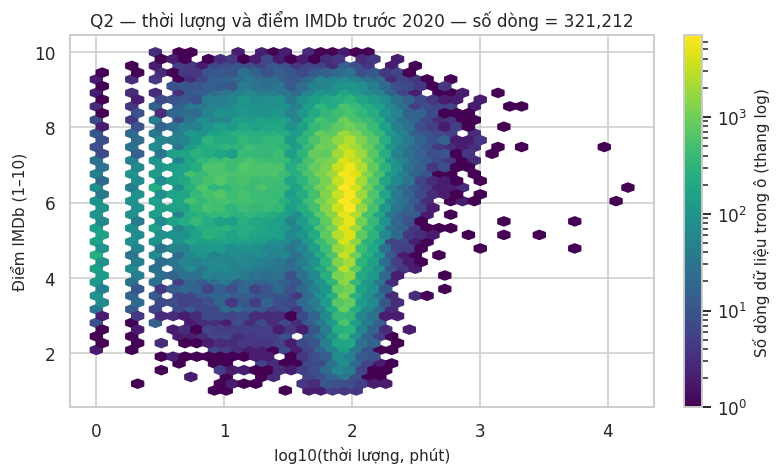

In [38]:
ml_runtime = ml_train.loc[ml_train.runtime.gt(0)]
fig, ax = plt.subplots(figsize=(7, 4.2), layout='constrained')
hb = ax.hexbin(np.log10(ml_runtime.runtime), ml_runtime.averageRating,
               gridsize=45, mincnt=1, bins='log', cmap='viridis')
ax.set(title=f'Q2 — thời lượng và điểm IMDb trước 2020 — số dòng = {len(ml_runtime):,}',
       xlabel='log10(thời lượng, phút)', ylabel='Điểm IMDb (1–10)')
fig.colorbar(hb, ax=ax, label='Số dòng dữ liệu trong ô (thang log)')
plt.show()

Các ô có nhiều dòng nhất nằm quanh thời lượng 100 phút và điểm IMDb khoảng 6–7. Quanh 100 phút vẫn có cả điểm thấp lẫn điểm cao. Trong mẫu này, điểm IMDb chưa cho thấy xu hướng tăng đều khi thời lượng dài hơn.

#### Thể loại và ngôn ngữ gốc

Mỗi chấm là điểm IMDb trung vị và đoạn ngang là khoảng tứ phân vị 25–75%. Nhãn nhóm ghi số dòng dữ liệu. Hình thể loại hiển thị tám nhãn phổ biến nhất và nhóm thiếu thể loại. Một tác phẩm có thể góp mặt ở nhiều thể loại, mỗi thể loại tính tác phẩm đó một lần. Hình ngôn ngữ hiển thị tám mã phổ biến nhất và gom các mã còn lại để dễ đọc.

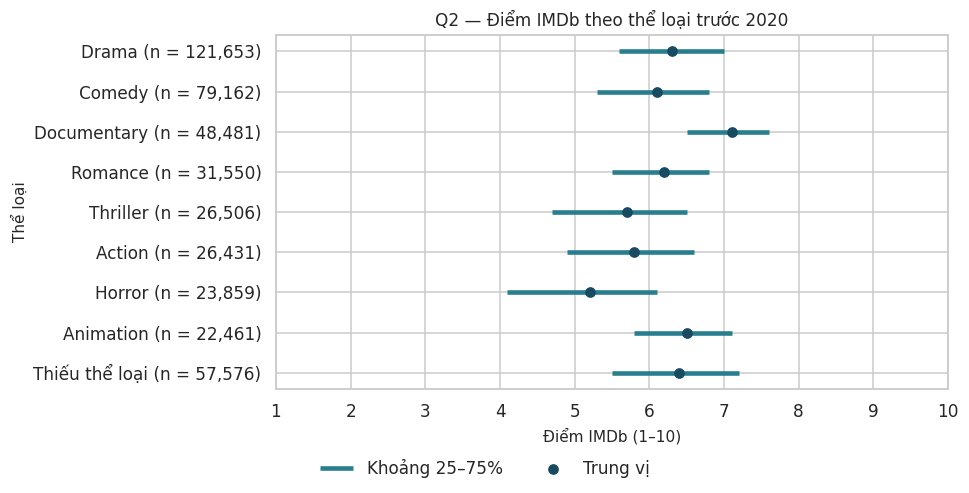

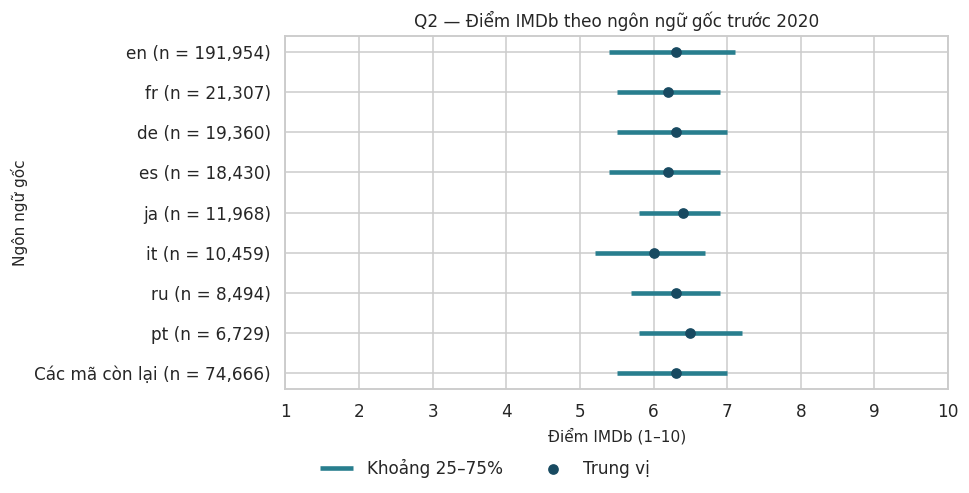

In [39]:
rating_summary = {
    'n': 'size',
    'median': 'median',
    'p25': lambda scores: scores.quantile(.25),
    'p75': lambda scores: scores.quantile(.75),
}

genre_ratings = ml_train[['genre_list', 'averageRating']].explode('genre_list')
top_ml_genres = genre_ratings.genre_list.value_counts().head(8).index.tolist()
genre_ratings['genre_list'] = genre_ratings.genre_list.fillna('Thiếu thể loại')

language_ratings = ml_train[['original_language', 'averageRating']].copy()
language = language_ratings.original_language
top_ml_languages = language.value_counts().head(8).index.tolist()
language_ratings['original_language'] = (
    language.where(language.isin(top_ml_languages), 'Các mã còn lại')
    .where(language.notna(), 'Thiếu ngôn ngữ')
)

category_plots = [
    (genre_ratings, 'genre_list', top_ml_genres + ['Thiếu thể loại'], 'Thể loại'),
    (language_ratings, 'original_language', top_ml_languages + ['Các mã còn lại', 'Thiếu ngôn ngữ'], 'Ngôn ngữ gốc'),
]
for ratings, group_col, order, label in category_plots:
    stats = (ratings.groupby(group_col).averageRating.agg(**rating_summary)
             .reindex(order).dropna(subset=['n']))
    positions = np.arange(len(stats))
    labels = [f'{group} (n = {row.n:,.0f})' for group, row in stats.iterrows()]

    fig, ax = plt.subplots(figsize=(8.7, 4.4), layout='constrained')
    ax.hlines(positions, stats.p25, stats.p75, color='#287e8e', linewidth=3,
              label='Khoảng 25–75%')
    ax.scatter(stats['median'], positions, color='#184a61', zorder=3, label='Trung vị')
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.set(title=f'Q2 — Điểm IMDb theo {label.lower()} trước 2020',
           xlabel='Điểm IMDb (1–10)', ylabel=label, xlim=(1, 10))
    fig.legend(loc='outside lower center', ncols=2, frameon=False)
    plt.show()

#### Năm phát hành

Biểu đồ điểm IMDb dùng các năm có ít nhất 100 dòng dữ liệu để trình bày trung vị và khoảng tứ phân vị. Biểu đồ số dòng dữ liệu dùng toàn bộ các năm có dữ liệu trước 2020 và dùng thang log cho trục tung. Ngưỡng 100 chỉ áp dụng khi vẽ biểu đồ điểm.

Các hình mô tả mối liên hệ riêng giữa từng thuộc tính và điểm IMDb. Mức đóng góp của từng thuộc tính vào dự đoán sẽ được đánh giá sau khi huấn luyện mô hình.

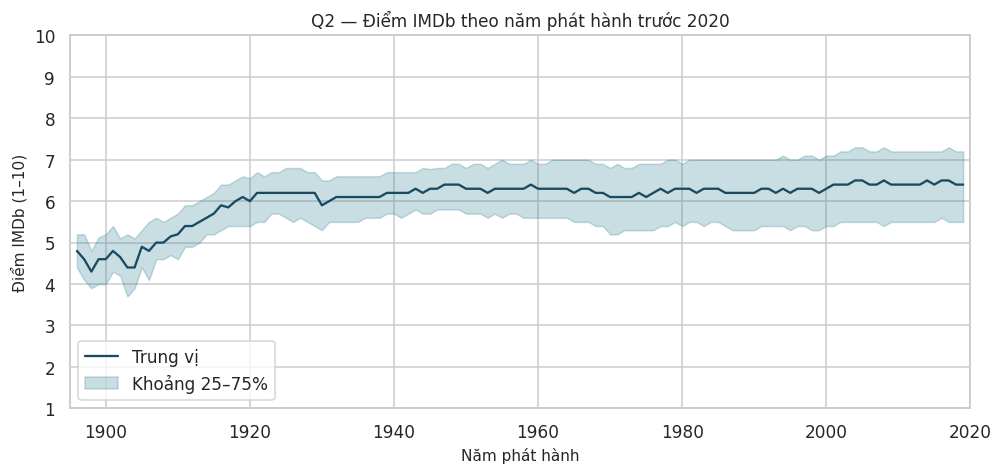

**Nhận xét.** Năm 1896, trung vị là 4.8 điểm. Từ năm 1920 đến 2019, trung vị theo năm dao động khoảng 5.9–6.5 điểm. Trong mẫu này, trung vị tăng ở những năm đầu được vẽ rồi dao động trong khoảng hẹp hơn.

In [40]:
release_year = ml_train.release_year.astype(int)
years = np.arange(release_year.min(), release_year.max() + 1)
ratings_by_year = ml_train.groupby(release_year).averageRating.agg(**rating_summary).reindex(years)

annual_scores = ratings_by_year.loc[ratings_by_year.n.ge(100), ['median', 'p25', 'p75']]
score_years = np.arange(annual_scores.index.min(), annual_scores.index.max() + 1)
annual_scores = annual_scores.reindex(score_years)

fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
ax.plot(score_years, annual_scores['median'], color='#184a61', label='Trung vị')
ax.fill_between(score_years, annual_scores.p25, annual_scores.p75,
                color='#287e8e', alpha=.25, label='Khoảng 25–75%')
ax.set(title='Q2 — Điểm IMDb theo năm phát hành trước 2020',
       xlabel='Năm phát hành', ylabel='Điểm IMDb (1–10)', ylim=(1, 10))
ax.set_xlim(score_years[0] - 1, score_years[-1] + 1)
ax.legend(loc='lower left')
plt.show()

first_score_year = score_years[0]
later_medians = annual_scores.loc[1920:, 'median']
display(Markdown(
    f'**Nhận xét.** Năm {first_score_year}, trung vị là '
    f'{annual_scores.loc[first_score_year, "median"]:.1f} điểm. '
    f'Từ năm 1920 đến {score_years[-1]}, trung vị theo năm dao động khoảng '
    f'{later_medians.min():.1f}–{later_medians.max():.1f} điểm. '
    'Trong mẫu này, trung vị tăng ở những năm đầu được vẽ rồi dao động trong khoảng hẹp hơn.'
))

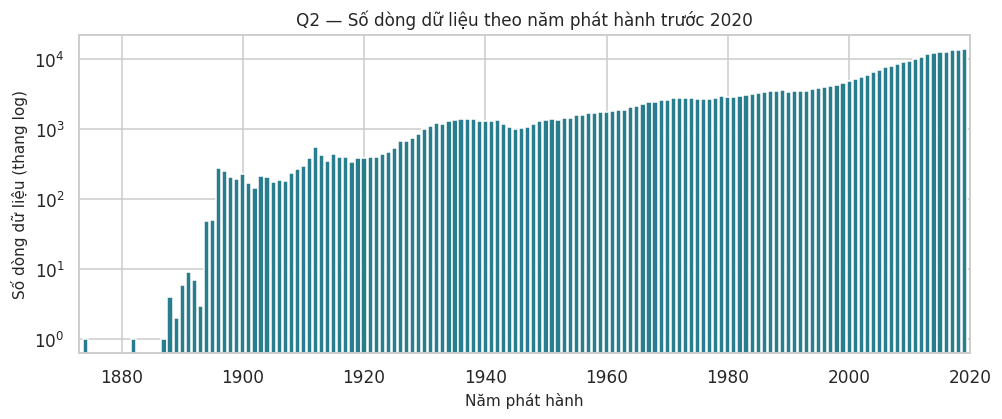

**Nhận xét.** Mẫu có 229 dòng dữ liệu cho năm 1900 và 13,947 dòng dữ liệu cho năm 2019. Số mẫu chênh lệch nhiều giữa các năm, nên cần đọc số dòng dữ liệu cùng thống kê điểm, nhất là khi so sánh với các năm đầu.

In [41]:
fig, ax = plt.subplots(figsize=(9, 3.7), layout='constrained')
ax.bar(years, ratings_by_year.n, color='#287e8e', width=.85)
ax.set(title='Q2 — Số dòng dữ liệu theo năm phát hành trước 2020',
       xlabel='Năm phát hành', ylabel='Số dòng dữ liệu (thang log)', yscale='log')
ax.set_xlim(years[0] - 1, years[-1] + 1)
plt.show()

display(Markdown(
    f'**Nhận xét.** Mẫu có {ratings_by_year.loc[1900, "n"]:,.0f} dòng dữ liệu cho năm 1900 '
    f'và {ratings_by_year.loc[2019, "n"]:,.0f} dòng dữ liệu cho năm 2019. '
    'Số mẫu chênh lệch nhiều giữa các năm, nên cần đọc số dòng dữ liệu cùng thống kê điểm, '
    'nhất là khi so sánh với các năm đầu.'
))

### 6.4. Thời lượng theo giai đoạn phát hành

Hình mô tả thời lượng của các dòng có nhãn thể loại trong mẫu Q3. Vùng tô biểu thị khoảng từ mốc 25% đến mốc 75%. Ba giai đoạn đầu gồm 10 năm mỗi giai đoạn, còn 2020–2024 gồm 5 năm.

In [42]:
runtime_sample = question_frames['Q3']
runtime_by_period = runtime_sample.groupby('period', observed=True).agg(
    n=('id', 'size'),
    trung_vi=('runtime', 'median'),
    p25=('runtime', lambda values: values.quantile(.25)),
    p75=('runtime', lambda values: values.quantile(.75)),
)

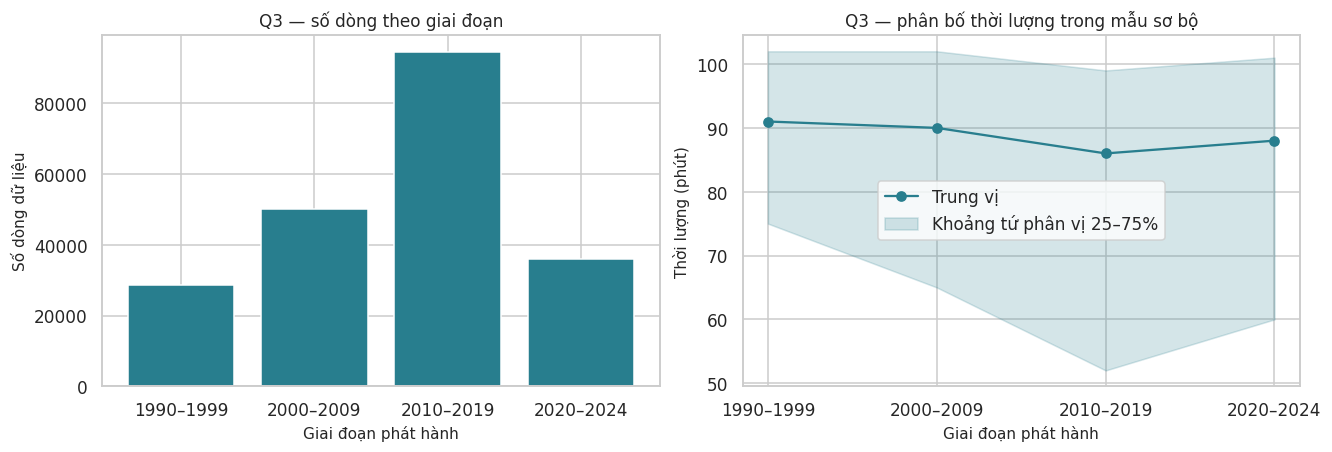

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
x = np.arange(len(runtime_by_period))
axes[0].bar(x, runtime_by_period['n'], color='#287e8e')
axes[0].set_xticks(x, runtime_by_period.index)
axes[0].set(title='Q3 — số dòng theo giai đoạn', xlabel='Giai đoạn phát hành', ylabel='Số dòng dữ liệu')
axes[1].plot(x, runtime_by_period.trung_vi, 'o-', color='#287e8e', label='Trung vị')
axes[1].fill_between(x, runtime_by_period.p25, runtime_by_period.p75, alpha=.2,
                     color='#287e8e', label='Khoảng tứ phân vị 25–75%')
axes[1].set_xticks(x, runtime_by_period.index)
axes[1].set(title='Q3 — phân bố thời lượng trong mẫu sơ bộ',
            xlabel='Giai đoạn phát hành', ylabel='Thời lượng (phút)')
axes[1].legend()
plt.show()

Mẫu có nhiều dòng nhất ở 2010–2019. Đây cũng là giai đoạn có trung vị thấp nhất, khoảng 86 phút, rồi tăng nhẹ lên 88 phút ở 2020–2024. Khoảng giữa của phân phối cũng rộng nhất ở 2010–2019.

Bảng dưới xét riêng các dòng có nhãn `Documentary`.

In [44]:
is_documentary = runtime_sample.genre_list.map(lambda genres: 'Documentary' in genres)
documentary_by_period = runtime_sample.loc[is_documentary].groupby('period', observed=True).runtime.agg(
    ['size', 'median']
)
display(documentary_by_period.rename(columns={
    'size': 'Số dòng dữ liệu',
    'median': 'Thời lượng trung vị (phút)',
}).rename_axis('Giai đoạn'))

,Số dòng dữ liệu,Thời lượng trung vị (phút)
Giai đoạn,,
1990–1999,3684,60.0
2000–2009,10668,72.0
2010–2019,21522,76.0
2020–2024,8475,80.0


Ở nhóm phim tài liệu, trung vị tăng qua cả bốn giai đoạn, từ 60 lên 80 phút. Xu hướng của nhóm này khác mẫu chung.

### 6.5. Ngân sách, doanh thu và độ phủ của mẫu tài chính

Mẫu tài chính gồm các dòng ghi năm phát hành trong giai đoạn 1990–2024 có thể loại và cả ngân sách lẫn doanh thu dương. Các giá trị 1 và 2 vẫn được tính trong khảo sát. Các trục tài chính dùng số ghi trong CSV vì đơn vị tiền tệ đang cần xác minh.

In [45]:
finance = question_frames['Q4'].copy()
english_share_raw = movies.original_language.eq('en').mean()
english_share_q4 = finance.original_language.eq('en').mean()
small_finance_mask = finance[['budget', 'revenue']].isin([1, 2]).any(axis=1)
display(Markdown(
    f'Mẫu tài chính có **{len(finance):,} dòng dữ liệu** ({len(finance)/n:.2%} CSV), '
    f'gồm **{small_finance_mask.sum():,}** dòng có ngân sách hoặc doanh thu bằng 1 hoặc 2. '
    f'Tỷ lệ dòng có ngôn ngữ gốc tiếng Anh là **{english_share_q4:.2%}** trong mẫu tài chính '
    f'và **{english_share_raw:.2%}** trong CSV gốc, chênh '
    f'**{100 * (english_share_q4 - english_share_raw):.2f} điểm phần trăm**.'))

Mẫu tài chính có **8,049 dòng dữ liệu** (1.81% CSV), gồm **37** dòng có ngân sách hoặc doanh thu bằng 1 hoặc 2. Tỷ lệ dòng có ngôn ngữ gốc tiếng Anh là **72.68%** trong mẫu tài chính và **54.76%** trong CSV gốc, chênh **17.92 điểm phần trăm**.

Trong bảng chéo, mỗi dòng có nhiều nhãn được tính một lần cho từng thể loại tương ứng.

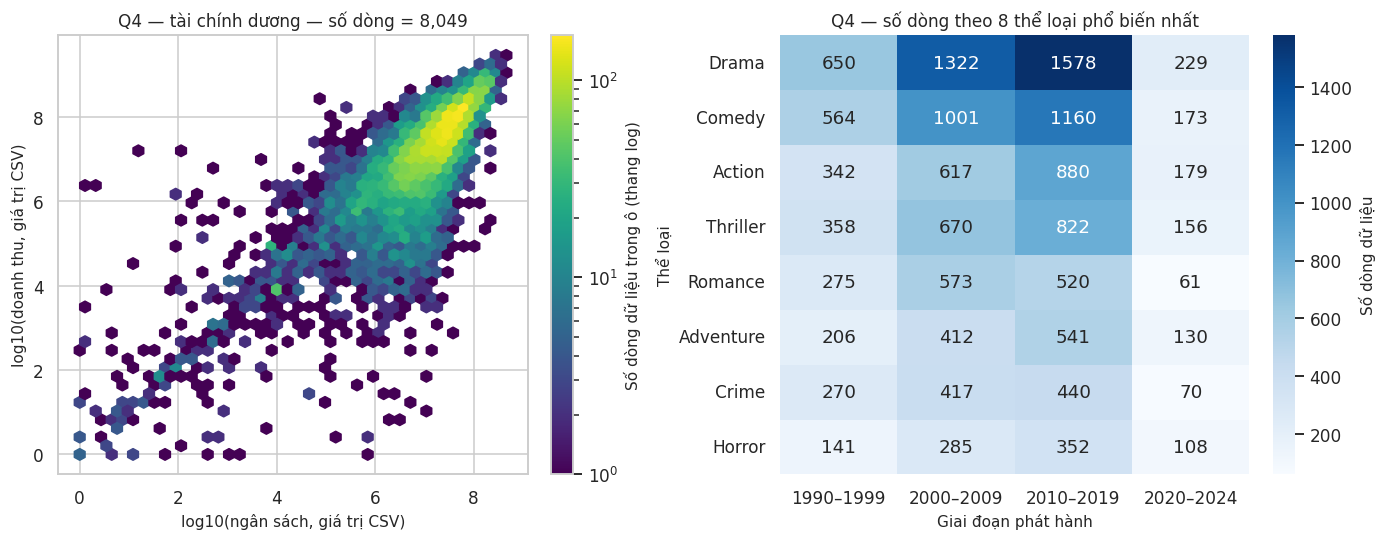

In [46]:
finance_log = np.log10(finance[['budget', 'revenue']])
finance_genres = finance[['period', 'genre_list']].explode('genre_list')
top_finance_genres = finance_genres.genre_list.value_counts().head(8).index
finance_genre_period_counts = pd.crosstab(
    finance_genres.genre_list, finance_genres.period
).reindex(top_finance_genres)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout='constrained')
hb = axes[0].hexbin(finance_log.budget, finance_log.revenue, gridsize=40,
                    mincnt=1, bins='log', cmap='viridis')
axes[0].set(title=f'Q4 — tài chính dương — số dòng = {len(finance):,}',
            xlabel='log10(ngân sách, giá trị CSV)', ylabel='log10(doanh thu, giá trị CSV)')
fig.colorbar(hb, ax=axes[0], label='Số dòng dữ liệu trong ô (thang log)')
sns.heatmap(finance_genre_period_counts, annot=True, fmt='d', cmap='Blues',
            ax=axes[1], cbar_kws={'label': 'Số dòng dữ liệu'})
axes[1].set(title='Q4 — số dòng theo 8 thể loại phổ biến nhất',
            xlabel='Giai đoạn phát hành', ylabel='Thể loại')
plt.show()

Trong mẫu tài chính, ngân sách cao thường đi cùng doanh thu cao, nhưng ở cùng mức ngân sách, doanh thu vẫn trải rộng. Bảy trong tám thể loại hiển thị có nhiều dòng nhất vào 2010–2019. Giai đoạn 2020–2024 có ít dòng hơn ở cả tám thể loại và chỉ kéo dài 5 năm.

### 6.6. Tương quan Spearman trong mẫu tài chính đã lọc

Heatmap dùng mẫu Q4 rồi giữ thêm thời lượng dương, hai điểm hợp lệ, lượt chấm dương ở cả hai bên và đủ tám giá trị hữu hạn. Bảng lọc cho biết mẫu thay đổi ra sao. Mọi hệ số trong hình dùng cùng một tập dòng dữ liệu.

Spearman mô tả mức đi cùng nhau theo thứ hạng. Hệ số dương gần 1 nghĩa là các dòng có giá trị cao ở cột này thường cũng có giá trị cao ở cột kia. Hệ số mô tả mẫu tài chính đầy đủ đã lọc.

In [47]:
corr_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'averageRating',
             'vote_count', 'numVotes', 'popularity']
corr_index = question_frames['Q4'].index
corr_candidates = movies.loc[corr_index, corr_cols]
corr_selected = pd.Series(True, index=corr_index)
corr_steps = [
    ('Thời lượng dương', corr_candidates.runtime.gt(0)),
    ('Điểm hợp lệ và có lượt chấm ở cả hai bên',
     corr_candidates.vote_average.between(0, 10)
     & corr_candidates.averageRating.between(1, 10)
     & corr_candidates.vote_count.gt(0) & corr_candidates.numVotes.gt(0)),
    ('Đủ tám giá trị hữu hạn', np.isfinite(corr_candidates).all(axis=1)),
]
corr_flow_rows = [['Mẫu Q4', len(corr_index), 0]]
for label, condition in corr_steps:
    before = int(corr_selected.sum())
    corr_selected &= condition
    after = int(corr_selected.sum())
    corr_flow_rows.append([label, after, before - after])
corr_flow = pd.DataFrame(corr_flow_rows, columns=['Điều kiện thêm vào', 'Số dòng còn lại', 'Số dòng loại thêm'])
display(corr_flow)

,Điều kiện thêm vào,Số dòng còn lại,Số dòng loại thêm
0,Mẫu Q4,8049,0
1,Thời lượng dương,7979,70
2,Điểm hợp lệ và có lượt chấm ở cả hai bên,7779,200
3,Đủ tám giá trị hữu hạn,7779,0


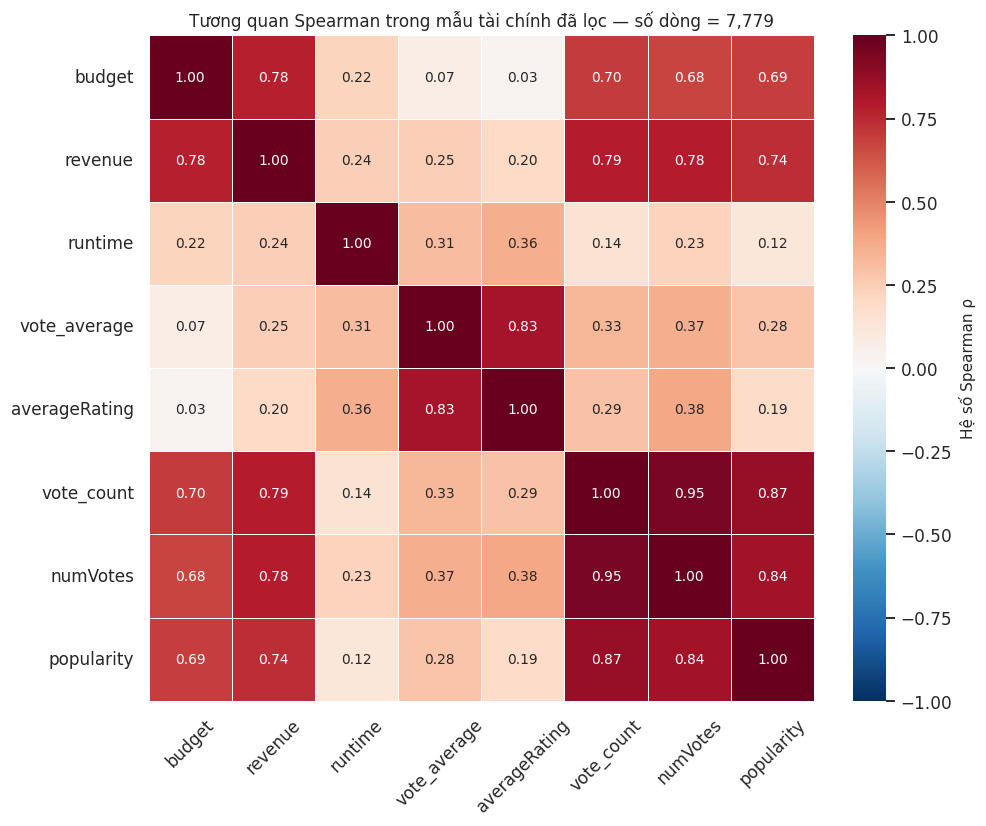

In [48]:
correlation_sample = corr_candidates.loc[corr_selected]
corr_matrix = correlation_sample.corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7.4), layout='constrained')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, square=True, linewidths=.4,
            ax=ax, cbar_kws={'label': 'Hệ số Spearman ρ'}, annot_kws={'fontsize': 9})
ax.set(title=f'Tương quan Spearman trong mẫu tài chính đã lọc — số dòng = {len(correlation_sample):,}')
ax.tick_params(axis='x', labelrotation=45)
ax.tick_params(axis='y', labelrotation=0)
plt.show()

In [49]:
display(Markdown(
    f'Trong **{len(correlation_sample):,} dòng** của mẫu tài chính đã lọc, '
    f'số lượt chấm TMDB và IMDb có tương quan mạnh (**{corr_matrix.loc["vote_count", "numVotes"]:.2f}**). '
    f'Ngân sách và doanh thu cũng thường tăng cùng nhau (**{corr_matrix.loc["budget", "revenue"]:.2f}**). '
    f'Tương quan giữa ngân sách và điểm IMDb chỉ khoảng **{corr_matrix.loc["budget", "averageRating"]:.2f}**. '
    'Trong mẫu này, ngân sách cao đi cùng doanh thu cao rõ hơn nhiều so với điểm IMDb cao.'
))

Trong **7,779 dòng** của mẫu tài chính đã lọc, số lượt chấm TMDB và IMDb có tương quan mạnh (**0.95**). Ngân sách và doanh thu cũng thường tăng cùng nhau (**0.78**). Tương quan giữa ngân sách và điểm IMDb chỉ khoảng **0.03**. Trong mẫu này, ngân sách cao đi cùng doanh thu cao rõ hơn nhiều so với điểm IMDb cao.

## 7. Tóm tắt khám phá và hướng tiền xử lý

### 7.1. Năm quan sát chính

Các số dưới đây được tính từ lần chạy notebook. Phạm vi mỗi quan sát gắn với mẫu và điều kiện đã ghi ở mục 6.

In [50]:
notes = [
    f'**Mã phim và dòng lặp.** CSV có {n:,} dòng, {movies.shape[1]} cột, '
    f'{int(movies.id.duplicated().sum()):,} dòng lặp sau lần đầu theo TMDb và '
    f'{int(movies.tconst.duplicated().sum()):,} theo IMDb. Mẫu hai mã chỉ xuất hiện một lần còn {len(analysis_base):,} dòng.',
    f'**Ngày và thể loại.** Thiếu ngày ở {int(missing.release_date.sum()):,} dòng ({missing.release_date.mean():.2%}), '
    f'thiếu thể loại ở {int(missing.genres.sum()):,} dòng ({missing.genres.mean():.2%}). '
    f'{joint_missing:,} dòng thiếu cả hai. Sau khi bỏ nhãn lặp trong mỗi dòng, có {int(genre_count.gt(1).sum()):,} dòng đa thể loại.',
    f'**Điểm và lượt chấm.** Q1 có {rating_coverage.loc[10]:,} cặp điểm ở ngưỡng 10 lượt mỗi bên, '
    f'còn {rating_coverage.loc[100]:,} ở ngưỡng 100. '
    f'Q2 có {len(ml_train):,} dòng trước 2020 và {len(ml_test):,} dòng trong 2020–2025.',
    f'**Thời lượng.** Q3 có {len(runtime_sample):,} tác phẩm có ghi thể loại, trong đó {runtime_sample.runtime.lt(60).mean():.2%} '
    f'ngắn hơn 60 phút. Trung vị qua bốn giai đoạn lần lượt là '
    f'{", ".join(f"{value:g}" for value in runtime_by_period.trung_vi)} phút. '
    'Tác phẩm có nhãn phim tài liệu cho xu hướng khác mẫu chung.',
    f'**Tài chính.** Ngân sách bằng 0 ở {movies.budget.eq(0).mean():.2%} CSV và doanh thu bằng 0 ở '
    f'{movies.revenue.eq(0).mean():.2%}. Q4 còn {len(finance):,} tác phẩm ({len(finance)/n:.2%} CSV), '
    f'trong đó {finance.original_language.eq("en").mean():.2%} có ngôn ngữ gốc en. '
    'Phạm vi tài chính, tiền tệ và nhóm ngân sách còn cần xác minh trước khi so doanh thu.',
]
display(Markdown('\n\n'.join(f'{i}. {note}' for i, note in enumerate(notes, 1))))

1. **Mã phim và dòng lặp.** CSV có 443,656 dòng, 29 cột, 13,894 dòng lặp sau lần đầu theo TMDb và 16,995 theo IMDb. Mẫu hai mã chỉ xuất hiện một lần còn 425,189 dòng.

2. **Ngày và thể loại.** Thiếu ngày ở 25,363 dòng (5.72%), thiếu thể loại ở 83,813 dòng (18.89%). 20,069 dòng thiếu cả hai. Sau khi bỏ nhãn lặp trong mỗi dòng, có 171,180 dòng đa thể loại.

3. **Điểm và lượt chấm.** Q1 có 77,674 cặp điểm ở ngưỡng 10 lượt mỗi bên, còn 18,056 ở ngưỡng 100. Q2 có 363,367 dòng trước 2020 và 43,911 dòng trong 2020–2025.

4. **Thời lượng.** Q3 có 209,322 tác phẩm có ghi thể loại, trong đó 24.84% ngắn hơn 60 phút. Trung vị qua bốn giai đoạn lần lượt là 91, 90, 86, 88 phút. Tác phẩm có nhãn phim tài liệu cho xu hướng khác mẫu chung.

5. **Tài chính.** Ngân sách bằng 0 ở 93.16% CSV và doanh thu bằng 0 ở 96.25%. Q4 còn 8,049 tác phẩm (1.81% CSV), trong đó 72.68% có ngôn ngữ gốc en. Phạm vi tài chính, tiền tệ và nhóm ngân sách còn cần xác minh trước khi so doanh thu.

### 7.2. Hướng tiền xử lý và phân tích tiếp

Các vấn đề cần lưu ý gồm mã lặp, thiếu ngày và thể loại, số 0 tài chính và thời lượng, điểm và lượt chấm chưa nhất quán, cùng ngày phát hành cần đối chiếu trạng thái. Nguyên nhân thiếu chưa được xác minh cho từng dòng. Mục 3.4 nêu cách rà hoặc lọc ngoại lệ.

Q1 và Q2 chỉ dùng dòng có ngày phát hành đọc được và năm đến hết 2025. Q2 dùng năm để chia tập huấn luyện và kiểm tra. Q3 và Q4 dùng năm phát hành để chia giai đoạn. Các dòng thiếu thông tin ở cột văn bản, đường dẫn ảnh, công ty, quốc gia, ngôn ngữ sử dụng hoặc thông tin ê-kíp vẫn được xét theo điều kiện của từng Q vì các cột đó nằm ngoài phạm vi phân tích hiện tại.

| Câu | Cách xử lý dữ liệu và bước phân tích tiếp theo |
| --- | --- |
| Q1 | Giữ cặp điểm trong thang và đủ lượt chấm. Dùng cả phim thiếu thể loại để so điểm chung và chỉ dùng phim có nhãn để so theo thể loại. Khi so điểm, nhóm dự kiến đối chiếu chênh lệch, tỷ lệ mỗi bên chấm cao hơn và độ nhạy theo ngưỡng lượt chấm. |
| Q2 | Cần điểm IMDb hợp lệ làm mục tiêu. Mẫu khám phá giữ phim thiếu thể loại hoặc có thời lượng 0. Khi xây mô hình, nhóm dự kiến mã hóa thể loại thiếu, đánh dấu thời lượng thiếu và điền bằng trung vị học từ tập huấn luyện. Việc gom nhãn ngôn ngữ hiếm và xử lý nhãn mới sẽ nằm trong Pipeline. |
| Q3 | Dùng thời lượng dương và dùng phim có nhãn cho bảng theo thể loại. Nhóm dự kiến so xu hướng theo thể loại và ngôn ngữ, đối chiếu ảnh hưởng của điều kiện có nhãn thể loại, rồi thử mốc độ dài và quy tắc xử lý cực trị. |
| Q4 | Dùng mẫu có thể loại, ngân sách và doanh thu dương. Đếm riêng số 0 trong báo cáo chất lượng. Nhóm cần xác minh tiền tệ và phạm vi doanh thu, kiểm tra độ nhạy với giá trị 1, 2 và chọn cách so sánh các phim có ngân sách tương đồng. |